<a href="https://colab.research.google.com/github/Dragmann/portpolio/blob/main/microstructure_hardness_regression_noiseaug.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 미세구조 이미지 → 경도(Hardness) 회귀 모델 — 조건 기반 재설계
문제 설명서(합성 미세구조 기반 재료 물성 예측 AI 경진대회)가 짚은 **5가지 미세구조 조건을 직접 측정하는 지표(K)** 를 설계의 중심에 두고, 각 조건이 경도를 어느 방향으로 바꾸는지 **학습 데이터로 확인한 뒤** 모델에 넣습니다. 기존의 ResNet18 특징(A·B), 범용 미세구조 특징(C), 미세조정(F)은 비교 후보로 그대로 두고, CNN과 직접 비교할 **사전학습 ViT 특징(V)** 을 더했습니다.

- 입력: 학습용 256×256 흑백 미세구조 이미지 500장 + 경도값, 예측용 이미지 1000장
- 출력: `ID,hardness` 형식 1000행 2열 (화면 출력 + `submission.csv` 저장), 평가는 RMSE

### 조건 재정리 (설명서 + 학습 데이터 기준)
| 조건 | 처음 해석 | 바로잡은 정의 | 학습 데이터 결과 (다른 조건 고정 시, 표준편차 1만큼 커질 때) |
|---|---|---|---|
| 1 결정립 크기 | 명암이 자주 바뀔수록(잘수록) 경도 ↑ | 결정립 크기(Hall-Petch는 "다른 조건이 같다면" 성립하는 경향). 명암 변화에는 촬영 노이즈도 섞이므로 노이즈를 걷어낸 결정립 지도에서 잰다 | **오히려 조대할수록 ↑** (+3.1 HV) |
| 2 어두운 영역 | 짙은 색이 많을수록 경도 ↑ | **어두운 결정립(2상)** 만. 기공·결정립계 선은 제외 | **가장 강한 요인, ↑** (+8.3 HV) |
| 3 기공 | 가장 짙은 부분, 방향은 데이터로 | 그대로 (작고 매우 어두운 덩어리) | 약하게 ↓ (−1.2 HV, 지표에 따라 95% 구간이 0에 걸침) |
| 4 균일성 | 명암 분포가 균일한지 | 설명서 기준 **결정립 크기 분포**와 공간적 불균일성 (명암 균일성은 조건 2와 겹침) | 뚜렷한 효과 없음 (+1.0 HV, 구간이 0에 걸침) |
| 5 둥근/길쭉 | 한 점 기준으로 둥글게 퍼졌는지 길게 정렬됐는지 | 그대로. 단 **절대 방향이 아니라 정렬 정도**만 사용 | **길쭉할수록 ↑** (+2.6 HV) |

경도와 무관한 **촬영 조건**(노이즈, 흐림, 밝기)은 측정을 왜곡하므로 따로 재서 함께 넣습니다. 수치는 이 노트북 5단계 표와 같은 계산입니다.

### 진행 순서
1~2. 데이터 준비 → 256×256 행렬 · 2-1. **촬영 상태 묶음** (선명 / 잡음 많음 / 대비 낮음) · 3. 교차검증 분할 (**세 묶음이 고르게** 들어가도록)
4. **조건별 지표(K)** 측정 · 5. **조건 검증** (방향·세기·기여도) · 5-1. **묶음별 조건 태그** (결정립 크기·어두운 상·기공·정렬)
6. ResNet18 특징(A·B) · 6-1. **EfficientNet-B0·VGG-16 특징(EN·VG)** · 6-2. **사전학습 ViT 특징(V1·V·V8)** · 6-3. **두 번째 사전학습 모델 특징(S)** · 7. 범용 미세구조 특징(C)
8. Ridge 후보 비교 (A, B, **EN, VG, V1, V, V8, S**, C, **K, C+K, 촬영 조건별 눈금 맞춘 C+K(CKr)**, B+C+K, 평균) + **묶음별 오차** · 8-1. **묶음별 모델 vs 통합 모델**
9. **미세조정(F, 기본 DINOv2)** 과 최종 선택 (여러 모델 평균 포함) · 10. 최종 학습·예측 · 11. 출력

### 실행 방법
1. 메뉴 **런타임 → 런타임 유형 변경 → GPU** (ViT 특징 V와 두 번째 모델 특징 S는 GPU에서만 자동 실행. 미세조정 F는 기본으로 꺼져 있음)
2. 데이터를 구글 드라이브에 올리기 (폴더 또는 zip 하나) → 아래 **설정** 셀의 `DRIVE_PATH` 수정
3. **런타임 → 모두 실행**

특징·미세조정 결과는 드라이브의 `<데이터 폴더 이름>_cache` 폴더(기본 `MyDrive/hardness_data_cache`)에 저장되어, 새 런타임이나 새 노트북에서도 다시 계산하지 않고 불러옵니다 (`CACHE_ON_DRIVE`).

데이터 폴더 구성은 자유롭습니다. 이름이 `TRAIN_…` / `TEST_…` 로 시작하는 이미지와, 학습 이미지 ID·경도값이 든 CSV(또는 엑셀)만 있으면 자동으로 찾습니다. (`sample_submission.csv` 같은 제출 양식이 있으면 그 순서와 열 이름을 그대로 따릅니다.)

In [ ]:
# ============================== 설정 ==============================
# 데이터 위치
DATA_SOURCE = 'drive'      # 'drive' : 구글 드라이브의 폴더/zip | 'upload' : 직접 업로드 | 'local' : 이미 LOCAL_DIR 에 있음
DRIVE_PATH  = '/content/open.zip'   # 드라이브 안 데이터 폴더 또는 zip 파일 경로
LOCAL_DIR   = '/content/data'                           # 작업용 폴더 (여기로 복사·압축 해제)
CACHE_ON_DRIVE = True    # 특징·미세조정 결과를 드라이브의 '<데이터 폴더 이름>_cache' 폴더에 저장 → 새 런타임·새 노트북에서도 다시 계산하지 않음

# 자동 탐지가 실패할 때만 직접 지정 (None 이면 자동)
TRAIN_LABEL_FILE = None    # 예: '/content/data/train.csv'
ID_COL           = None    # 예: 'ID'
TARGET_COL       = None    # 예: 'hardness'

# 실험 설정
SEED       = 42
N_FOLDS    = 5       # 교차검증 fold 수
N_REPEATS  = 3       # 교차검증 반복 횟수
USE_TTA    = True    # 회전·뒤집기 8방향 평균 (CPU 에서 너무 느리면 False)
BATCH_SIZE = 32

# 촬영 상태 묶음 (선명 / 잡음 많음 / 대비 낮음)
GROUP_NOISE_SIGMA = 10.0   # 노이즈 σ 가 이보다 크고 흐림도 큰 이미지 = '잡음 많음' (이 데이터는 σ=10 에서 흐림이 계단처럼 커짐)
STRATIFY_GROUPS   = True   # 교차검증·400/100 분할에 세 묶음이 고르게 들어가도록 층화
RUN_GROUP_MODELS  = True   # 묶음마다 따로 학습한 모델(@G)도 만들어 통합 모델과 비교 (8-1단계)

# 미세조정(F) 설정: 사전학습 모델 전체를 경도 예측에 맞게 다시 학습
RUN_FINETUNE   = 'auto'               # 'auto' : GPU 가 있을 때만 실행 | True : 항상 실행 | False : 건너뜀
FT_BACKBONE    = 'dinov2_vitl14_reg'  # 'dinov2_vitb14_reg'(작고 빠름) | 'dinov2_vitl14_reg' | 'resnet18' | 'efficientnet_b0' | 'vgg16'
FT_EPOCHS      = 20       # fold 마다 학습 epoch 수 (고정, 검증 fold 로 고르지 않음)
FT_BATCH       = 16       # GPU 메모리가 부족하면 8
FT_LR          = None     # 백본 (맨 위층) 학습률. None 이면 자동: DINOv2 2e-5, CNN(resnet18·efficientnet_b0·vgg16) 1e-4
FT_HEAD_LR     = 1e-3     # 새로 붙인 출력층 학습률
FT_LAYER_DECAY = 0.75     # DINOv2: 아래층으로 갈수록 학습률을 줄이는 비율 (12블록 기준, 깊이에 맞춰 자동 조정)
FT_DROP_PATH   = 0.1      # DINOv2: 학습 중 블록을 무작위로 건너뛰는 비율 (과적합 방지)
FT_CROP        = 224      # 학습 때 무작위로 잘라낼 크기 (DINOv2 는 14의 배수. 예측은 가운데 252 또는 256 전체)
FT_SEEDS       = 3        # 서로 다른 시드로 몇 번 학습해 평균낼지 (1 이면 시간 1/3, 시드별 결과는 따로 캐시됨)

# 미세조정 증강 스위치 (기본값 = 무작위 자르기 + 90° 회전 + 좌우반전만 사용)
FT_ROTATE_ANY   = False   # True : 90° 단위 대신 0~360° 임의 각도 회전 (가장자리는 거울 반사로 채움)
FT_SCALE_JITTER = 0.0     # 예: 0.1 → 0.9~1.1배 확대·축소 (RandomResizedCrop 과 비슷, 결정립 크기가 바뀜)
FT_BRIGHTNESS   = 0.0     # 예: 0.2 → 밝기 0.8~1.2배
FT_CONTRAST     = 0.0     # 예: 0.2 → 대비 0.8~1.2배
FT_NOISE_AUG    = 0.5     # 깨끗한 학습 이미지에 '잡음 많음' 묶음처럼 흐림·잡음·조명 기울기를 입힐 확률 (0 = 끔)

# 다른 CNN 고정 특징(EN·VG) 설정
RUN_CNNS   = 'auto'                          # 'auto' : GPU 가 있을 때만 실행 | True : 항상 실행 | False : 건너뜀
EXTRA_CNNS = ['efficientnet_b0', 'vgg16']    # 비교할 CNN (EN = EfficientNet-B0, VG = VGG-16)

# 사전학습 ViT 특징(V) 설정
RUN_VIT   = 'auto'                # 'auto' : GPU 가 있을 때만 실행 | True : 항상 실행(CPU 는 매우 느림) | False : 건너뜀
VIT_MODEL = 'dinov2_vitg14_reg'   # 클수록 좋았음: 'dinov2_vitb14_reg' < 'dinov2_vitl14_reg' < 'dinov2_vitg14_reg' (가장 크고 느림)
VIT_SIZE  = 252                   # 입력 크기, 14의 배수. 252 = 원본 해상도(가장자리 2픽셀만 자름) | 504 = 2배 확대(약 5배 느림, ViT-g 에서 효과 없었음)

# 두 번째 사전학습 모델 특징(S) 설정 (DINOv2 와 학습 방식이 다른 모델로 평균 효과를 노림)
RUN_EXTRA   = False                                   # 'auto' : GPU 가 있을 때만 실행 | True : 항상 실행 | False : 건너뜀 (V 와 평균해도 나빠져서 기본은 끔)
EXTRA_MODEL = 'google/siglip-so400m-patch14-384'      # 또는 'openai/clip-vit-large-patch14-336' (OpenAI CLIP)

# 최종 선택: 1등과의 교차검증 RMSE 차이가 이 안이면 더 많은 모델을 평균한 후보를 고름 (0 = 무조건 1등)
ENSEMBLE_TOL = 0.05

# 출력 설정
DECIMALS   = 2                  # 경도 소수점 자리
OUTPUT_CSV = 'submission.csv'   # 저장 파일 이름

In [ ]:
# ========================= 라이브러리 / 환경 =========================
import os, re, zipfile, shutil, time, hashlib, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from scipy import ndimage as ndi
from scipy.optimize import least_squares
from scipy.stats import skew, kurtosis, norm
from skimage.morphology import disk
from skimage.feature import graycomatrix, graycoprops
from sklearn.model_selection import RepeatedKFold, RepeatedStratifiedKFold, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import RidgeCV
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from joblib import Parallel, delayed

import torch
import torchvision
from torchvision.models import resnet18, ResNet18_Weights
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights, vgg16, VGG16_Weights

try:
    from IPython.display import display
except ImportError:
    display = print

warnings.filterwarnings('ignore')
np.random.seed(SEED)
torch.manual_seed(SEED)

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'torch {torch.__version__} | torchvision {torchvision.__version__} | device = {DEVICE} | Colab = {IN_COLAB}')
if DEVICE == 'cpu':
    print('※ GPU가 없습니다. 런타임 → 런타임 유형 변경 → T4 GPU 를 권장합니다 (CPU도 동작은 합니다).')

torch 2.11.0+cu130 | torchvision 0.26.0+cu130 | device = cuda | Colab = True


## 1. 데이터 준비
드라이브(폴더/zip) 또는 업로드한 파일을 작업 폴더로 가져오고, 학습 이미지·예측 이미지·경도값 파일을 자동으로 찾습니다.

In [ ]:
def unzip_all(folder):
    """folder 안의 zip 파일을 모두 그 자리에서 압축 해제"""
    for z in list(Path(folder).rglob('*.zip')):
        if '__MACOSX' in z.parts:
            continue
        print(f'압축 해제: {z.name}')
        with zipfile.ZipFile(z) as zf:
            zf.extractall(z.parent)

os.makedirs(LOCAL_DIR, exist_ok=True)

if DATA_SOURCE == 'drive':
    if IN_COLAB:
        from google.colab import drive
        drive.mount('/content/drive')
    src = Path(DRIVE_PATH)
    if not src.exists():
        raise FileNotFoundError(f'DRIVE_PATH 가 없습니다: {src}\n왼쪽 파일 탐색기에서 경로를 확인해 설정 셀을 고쳐 주세요.')
    t0 = time.time()
    if src.is_file():
        shutil.copy(src, LOCAL_DIR)                              # zip 파일 하나
    else:
        shutil.copytree(src, LOCAL_DIR, dirs_exist_ok=True)      # 폴더 통째로 (드라이브에서 직접 읽는 것보다 빠름)
    print(f'드라이브 → {LOCAL_DIR} 복사 완료 ({time.time() - t0:.0f}s)')
elif DATA_SOURCE == 'upload':
    from google.colab import files
    print('zip 파일(또는 이미지·CSV 파일들)을 선택하세요.')
    for name in files.upload():
        shutil.move(name, os.path.join(LOCAL_DIR, os.path.basename(name)))
elif DATA_SOURCE != 'local':
    raise ValueError("DATA_SOURCE 는 'drive', 'upload', 'local' 중 하나여야 합니다.")

unzip_all(LOCAL_DIR)
DATA_DIR = Path(LOCAL_DIR)

Mounted at /content/drive
드라이브 → /content/data 복사 완료 (0s)
압축 해제: open.zip


In [ ]:
IMG_EXTS   = {'.png', '.jpg', '.jpeg', '.bmp', '.tif', '.tiff'}
TABLE_EXTS = {'.csv', '.xlsx', '.xls'}

def visible(p):
    return not any(part.startswith('.') or part == '__MACOSX' for part in p.relative_to(DATA_DIR).parts)

def find_images(prefix):
    """이름이 prefix(TRAIN/TEST)로 시작하는 이미지 → {ID: 경로}. 없으면 train/test 폴더 안의 이미지 사용"""
    imgs = [p for p in DATA_DIR.rglob('*') if p.suffix.lower() in IMG_EXTS and visible(p)]
    hit = [p for p in imgs if p.stem.upper().startswith(prefix)]
    if not hit:
        hit = [p for p in imgs if any(prefix.lower() in d.lower() for d in p.relative_to(DATA_DIR).parts[:-1])]
    out = {}
    for p in sorted(hit):
        out.setdefault(p.stem, p)          # 같은 이름이 여러 개면 첫 번째만
    return out

def read_table(p):
    if p.suffix.lower() == '.csv':
        for enc in ('utf-8-sig', 'cp949', 'latin1'):
            try:
                return pd.read_csv(p, encoding=enc)
            except UnicodeDecodeError:
                pass
    return pd.read_excel(p)

def to_id(v):
    """'train/TRAIN_000001.png' → 'TRAIN_000001'"""
    return Path(str(v).strip().replace('\\', '/')).stem

def match_column(df, keys, prefer=None):
    """값이 이미지 이름(keys)과 가장 많이 일치하는 열과 일치 개수"""
    best, best_n = None, 0
    for c in ([prefer] if prefer else df.columns):
        n = int(df[c].map(to_id).isin(keys).sum())
        if n > best_n:
            best, best_n = c, n
    return best, best_n

train_paths = find_images('TRAIN')
test_paths  = find_images('TEST')
print(f'학습 이미지 {len(train_paths)}장, 예측 이미지 {len(test_paths)}장 발견')
if not train_paths or not test_paths:
    raise RuntimeError(f'{DATA_DIR} 에서 TRAIN_/TEST_ 이미지를 찾지 못했습니다. 경로를 확인하세요.')

tables = [Path(TRAIN_LABEL_FILE)] if TRAIN_LABEL_FILE else \
         [p for p in DATA_DIR.rglob('*') if p.suffix.lower() in TABLE_EXTS and visible(p)]
label_info, sub_info = None, None
for p in tables:
    try:
        df = read_table(p)
    except Exception as e:
        print(f'읽기 실패: {p} ({e})')
        continue
    # (1) 학습 경도 파일: ID 열이 학습 이미지 이름과 일치 + 숫자형 경도 열
    c_id, n_id = match_column(df, set(train_paths), ID_COL)
    if n_id > 0:
        if TARGET_COL:
            c_y = TARGET_COL
        else:
            nums  = [c for c in df.columns if c != c_id and pd.api.types.is_numeric_dtype(df[c])]
            named = [c for c in nums if re.search(r'hard|경도|hv|target|label', str(c), re.I)]
            c_y = named[0] if named else (nums[0] if len(nums) == 1 else None)
        if c_y is not None and (label_info is None or n_id > label_info[3]):
            label_info = (p, c_id, c_y, n_id, df)
    # (2) 제출 양식: ID 열이 예측 이미지 이름과 일치 (동률이면 이름에 submission/sample 이 든 파일 우선)
    c_tid, n_tid = match_column(df, set(test_paths))
    rank = (n_tid, bool(re.search(r'sub|sample|제출', p.name, re.I)))
    if n_tid > 0 and (sub_info is None or rank > sub_info[2]):
        sub_info = (p, c_tid, rank, df)

if label_info is None:
    raise RuntimeError('학습 경도값 파일을 찾지 못했습니다. 설정 셀의 TRAIN_LABEL_FILE / ID_COL / TARGET_COL 을 직접 지정하세요.')

p_lab, c_id, c_y, _, df_lab = label_info
label_df = pd.DataFrame({'ID': df_lab[c_id].map(to_id),
                         'hardness': pd.to_numeric(df_lab[c_y], errors='coerce')})
label_df = label_df.dropna().drop_duplicates('ID')
label_df = label_df[label_df['ID'].isin(train_paths)].reset_index(drop=True)
print(f"경도 파일: {p_lab.name} (ID 열 '{c_id}', 경도 열 '{c_y}') → {len(label_df)}장 매칭")
no_label = sorted(set(train_paths) - set(label_df['ID']))
if no_label:
    print(f'※ 경도값이 없는 학습 이미지 {len(no_label)}장은 제외합니다. 예: {no_label[:3]}')

if sub_info is not None:
    p_sub, c_tid, _, df_sub = sub_info
    test_ids = [i for i in df_sub[c_tid].map(to_id) if i in test_paths]
    others = [c for c in df_sub.columns if c != c_tid]
    OUT_ID_COL, OUT_Y_COL = c_tid, (others[0] if len(others) == 1 else 'hardness')
    print(f"제출 양식: {p_sub.name} → 순서와 열 이름('{OUT_ID_COL}', '{OUT_Y_COL}')을 그대로 사용")
    missing = sorted(set(test_paths) - set(test_ids))
    if missing:
        print(f'※ 제출 양식에 없는 예측 이미지 {len(missing)}장은 뒤에 이어 붙입니다.')
        test_ids += missing
else:
    test_ids = sorted(test_paths)
    OUT_ID_COL, OUT_Y_COL = 'ID', 'hardness'
print(f'예측 대상 {len(test_ids)}장: {test_ids[0]} … {test_ids[-1]}')

학습 이미지 500장, 예측 이미지 1000장 발견
경도 파일: train.csv (ID 열 'ID', 경도 열 'hardness') → 500장 매칭
제출 양식: sample_submission.csv → 순서와 열 이름('ID', 'hardness')을 그대로 사용
예측 대상 1000장: TEST_000001 … TEST_001000


## 2. 이미지 → 256×256 행렬
흑백 8bit PNG는 이미 **픽셀마다 0(검정)~255(흰색)의 숫자**를 가진 256×256 행렬입니다. "같은 명암이면 같은 숫자, 다른 명암이면 다른 숫자"라는 원안의 조건이 그대로 만족되므로 따로 번호를 붙일 필요가 없습니다.

> 주의: 명암을 등장 순서대로 1, 2, 3… 같은 임의 번호(라벨 인코딩)로 바꾸면 "더 어둡다/더 밝다"는 순서와 간격 정보가 사라집니다. 결정립 경계와 석출물은 *어두운 정도*로 구분되므로 원래 값을 그대로 씁니다.

In [ ]:
def load_gray(path, size=256):
    """이미지 → (size, size) uint8 행렬 (값 0~255)"""
    im = Image.open(path)
    if im.mode.startswith('I;16') or im.mode in ('I', 'F'):      # 16bit·실수형이면 0~255 로 변환
        a = np.asarray(im, dtype=np.float32)
        a = a / 257.0 if a.max() > 255 else a
        im = Image.fromarray(np.clip(a, 0, 255).astype(np.uint8))
    im = im.convert('L')                                           # RGB 등이어도 흑백 1채널로
    if im.size != (size, size):
        im = im.resize((size, size), Image.BILINEAR)
    return np.asarray(im, dtype=np.uint8)

t0 = time.time()
train_ids = label_df['ID'].tolist()
y = label_df['hardness'].to_numpy(dtype=np.float64)
X_tr_img = np.stack([load_gray(train_paths[i]) for i in train_ids])    # (500, 256, 256)
X_te_img = np.stack([load_gray(test_paths[i]) for i in test_ids])      # (1000, 256, 256)
print(f'학습 행렬 {X_tr_img.shape}, 예측 행렬 {X_te_img.shape}, 자료형 {X_tr_img.dtype} ({time.time() - t0:.1f}s)')
print(f'경도: 평균 {y.mean():.2f}, 표준편차 {y.std():.2f}, 범위 {y.min():.2f} ~ {y.max():.2f}')
print(f'\n{train_ids[0]} 행렬의 왼쪽 위 8×8 (픽셀값 = 명암 0~255):')
print(X_tr_img[0, :8, :8])

학습 행렬 (500, 256, 256), 예측 행렬 (1000, 256, 256), 자료형 uint8 (1.7s)
경도: 평균 194.17, 표준편차 17.68, 범위 151.98 ~ 264.12

TRAIN_000001 행렬의 왼쪽 위 8×8 (픽셀값 = 명암 0~255):
[[157 169 154 164 156 161 167 157]
 [159 157 167 150 166 159 179 163]
 [172 166 154 180 150 168 157 171]
 [157 174 158 154 167 176 163 159]
 [173 175 149 153 158 164 163 149]
 [156 156 158 167 154 157 167 167]
 [153 153 169 154 163 168 162 164]
 [140 159 153 173 161 161 168 159]]


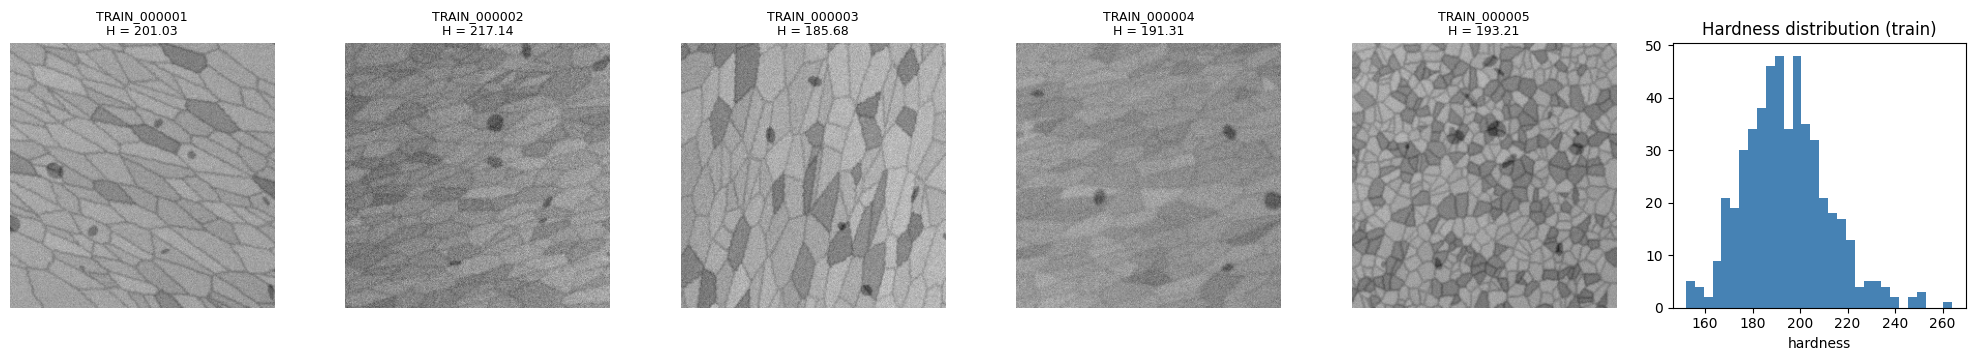

In [ ]:
fig, axes = plt.subplots(1, 6, figsize=(20, 3.6))
for k, ax in enumerate(axes[:5]):
    ax.imshow(X_tr_img[k], cmap='gray', vmin=0, vmax=255)
    ax.set_title(f'{train_ids[k]}\nH = {y[k]:.2f}', fontsize=9)
    ax.axis('off')
axes[5].hist(y, bins=30, color='steelblue')
axes[5].set_title('Hardness distribution (train)')
axes[5].set_xlabel('hardness')
plt.tight_layout()
plt.show()

## 2-1. 촬영 상태로 묶기 — 선명 / 잡음 많음 / 대비 낮음
학습 이미지를 촬영 상태에 따라 세 묶음으로 나누고, 같은 규칙을 예측 이미지에도 적용합니다. 손으로 고르는 대신 이미지마다 세 값을 잽니다.

- **노이즈 σ**: 픽셀마다 섞인 무작위 잡음의 크기 (0~255 눈금)
- **흐림 σ**: 파워 스펙트럼이 고주파 쪽에서 꺾이는 정도로 추정한 흐림 반경 (픽셀)
- **대비**: 노이즈를 걷어낸 이미지의 명암 폭(5~95 백분위) ÷ 밝기

| 묶음 | 규칙 | 이 데이터에서 확인한 것 |
|---|---|---|
| 잡음 많음 | 노이즈 σ > `GROUP_NOISE_SIGMA`(10)이고 흐림도 큰 이미지 | σ=10을 넘는 순간 흐림이 0.8px → 1.5px로 **계단처럼** 커집니다. 생성기의 별도 촬영 조건으로 보이며 학습·예측 모두 약 41%. 경도와는 무관 |
| 대비 낮음 | 나머지 중 대비가 중앙값보다 낮은 이미지 | 대비는 연속적이라 중앙값으로 둘로 나눔 |
| 선명 | 나머지 | |

> **주의 — '대비 낮음'은 촬영 조건이 아닙니다.** 결정립계 선의 진하기는 묶음과 상관없이 거의 같고, 대비 차이는 대부분 **어두운 결정립(2상)이 적거나 옅은 데서** 옵니다 (2상 지표 `c2_std_rel`과 상관 약 0.94). 2상은 경도의 가장 큰 요인이라 이 묶음은 경도가 낮은 쪽에 몰립니다. 그래서 묶음마다 모델을 따로 만들면 모델마다 학습 이미지가 1/3로 줄고 경도 범위도 잘립니다 → 8-1단계에서 같은 교차검증으로 직접 비교합니다.

In [ ]:
# ---------- 공통 도구: 특징 캐시, Ridge 교차검증 (이후 모든 단계에서 사용) ----------
if DATA_SOURCE == 'drive' and CACHE_ON_DRIVE:
    CACHE_DIR = Path(DRIVE_PATH).parent / f'{Path(DRIVE_PATH).stem}_cache'     # 예: MyDrive/hardness_data_cache
else:
    CACHE_DIR = DATA_DIR / 'feature_cache'
CACHE_DIR.mkdir(parents=True, exist_ok=True)
_old_cache = DATA_DIR / 'feature_cache'                  # 데이터 폴더에 함께 올려 둔 예전 캐시가 있으면 옮겨서 같이 씀
if _old_cache.exists() and _old_cache.resolve() != CACHE_DIR.resolve():
    _moved = 0
    for _f in _old_cache.iterdir():
        if _f.is_file() and not (CACHE_DIR / _f.name).exists():
            shutil.copy(_f, CACHE_DIR / _f.name)
            _moved += 1
    if _moved:
        print(f'데이터 폴더의 예전 캐시 {_moved}개를 캐시 폴더로 옮겼습니다.')
print(f'캐시 폴더: {CACHE_DIR} (파일 {sum(1 for _ in CACHE_DIR.iterdir())}개)')

def data_key(imgs):
    """이미지 묶음이 바뀌면 캐시도 새로 만들도록 간단한 지문 생성"""
    return hashlib.md5(imgs[::25].tobytes()).hexdigest()[:10] + f'_n{len(imgs)}'

def features_cached(fn, imgs, name, version):
    """이미지마다 fn(img) → dict 특징을 병렬로 계산하고 CSV 로 캐시"""
    f = CACHE_DIR / f'{version}_{name}_{data_key(imgs)}.csv'
    if f.exists():
        print(f'{version} {name}: 캐시 사용 ({f.name})')
        return pd.read_csv(f)
    t0 = time.time()
    df = pd.DataFrame(Parallel(n_jobs=-1, batch_size=8)(delayed(fn)(im) for im in imgs))
    df.to_csv(f, index=False)
    print(f'{version} {name}: {len(imgs)}장 → {df.shape[1]}개 ({time.time() - t0:.0f}s)')
    return df

def clean(tr_df, te_df):
    """inf/NaN 을 학습 데이터 중앙값으로 채워 float 행렬로"""
    tr_df, te_df = tr_df.replace([np.inf, -np.inf], np.nan), te_df.replace([np.inf, -np.inf], np.nan)
    fill = tr_df.median()
    return tr_df.fillna(fill).fillna(0.0), te_df.fillna(fill).fillna(0.0)

ALPHAS = np.logspace(-3, 7, 41)      # 특징이 수천 개인 후보(ViT 등)도 알맞은 alpha 를 찾도록 1e7 까지

def ridge_model():
    return make_pipeline(StandardScaler(), RidgeCV(alphas=ALPHAS))

def cv_oof(X):
    """반복 교차검증의 out-of-fold 예측: (반복 수, 샘플 수)"""
    oof = np.zeros((N_REPEATS, len(y)))
    for j, (tr, va) in enumerate(CV_SPLITS):
        oof[j // N_FOLDS, va] = ridge_model().fit(X[tr], y[tr]).predict(X[va])
    return oof

def cv_rmse(X):
    oof = cv_oof(np.asarray(X, dtype=np.float64))
    return float(np.mean([np.sqrt(np.mean((oof[r] - y) ** 2)) for r in range(N_REPEATS)]))

캐시 폴더: /content/open_cache (파일 0개)


In [ ]:
# ---------- 촬영 상태 측정: 노이즈 σ, 흐림 σ, 대비 ----------
_QR = np.rint(np.sqrt((np.fft.fftfreq(256) * 256)[:, None] ** 2 + (np.fft.fftfreq(256) * 256)[None, :] ** 2)).astype(int)
_QN = np.maximum(np.bincount(_QR.ravel(), minlength=182), 1)
_QF = np.arange(3, 129) / 256.0                                    # 공간 주파수 (주기/픽셀)
_LAP = np.array([[1, -2, 1], [-2, 4, -2], [1, -2, 1]], np.float64)

def quality_features(img):
    x = img.astype(np.float64)
    noise = np.sqrt(np.pi / 2) * np.abs(ndi.convolve(x, _LAP)[1:-1, 1:-1]).mean() / 6.0     # 노이즈 σ
    s = ndi.gaussian_filter(x, 2.0)                                                       # 노이즈를 걷어낸 구조
    med = max(float(np.median(s)), 1.0)
    p5, p95 = np.percentile(s, [5, 95])
    # 흐림: 반지름별 파워 스펙트럼 = A·f^(-β)·exp(-(2πσf)²) + 노이즈 바닥 을 맞춰 σ 추정 (흐릴수록 고주파가 빨리 꺼짐)
    P = np.abs(np.fft.fft2(x - x.mean())) ** 2 / x.size
    rad = np.maximum((np.bincount(_QR.ravel(), P.ravel(), minlength=182) / _QN)[3:129], 1e-6)
    def resid(th):
        logA, beta, sb, logN = th
        return np.log(np.exp(logA) * _QF ** (-beta) * np.exp(-(2 * np.pi * sb * _QF) ** 2) + np.exp(logN)) - np.log(rad)
    lo, hi = np.array([-50, 0.5, 0.0, -20.0]), np.array([50, 6.0, 20.0, 20.0])
    best = None
    for sb0 in (0.8, 1.5, 2.5):                                                           # 시작점 3개 중 가장 잘 맞는 것
        th0 = np.clip([np.log(rad[0] * _QF[0] ** 3), 3.0, sb0, np.log(rad[-10:].mean())], lo + 1e-6, hi - 1e-6)
        r = least_squares(resid, th0, bounds=(lo, hi))
        if best is None or r.cost < best.cost:
            best = r
    return {'noise': float(noise), 'blur': float(best.x[2]), 'contrast': float((p95 - p5) / med), 'brightness': med}

Q_tr = features_cached(quality_features, X_tr_img, 'train', 'quality_v1')
Q_te = features_cached(quality_features, X_te_img, 'test', 'quality_v1')

GROUP_CODES = ['sharp', 'noisy', 'lowcon']
GROUP_KO = {'sharp': '선명', 'noisy': '잡음 많음', 'lowcon': '대비 낮음'}
GROUP_EN = {'sharp': 'sharp', 'noisy': 'noisy (+blur)', 'lowcon': 'low contrast'}

def noisy_regime(Q):
    """잡음 많음 = 노이즈 σ 가 기준보다 크면서 흐림도 큰 이미지 (기준 바로 위 0.5 구간은 흐림으로 한 번 더 확인)"""
    n, b = Q['noise'].to_numpy(), Q['blur'].to_numpy()
    return (n > GROUP_NOISE_SIGMA + 0.5) | ((n > GROUP_NOISE_SIGMA) & (b > 1.0))

NOISY_TR, NOISY_TE = noisy_regime(Q_tr), noisy_regime(Q_te)
_clean_c = Q_tr['contrast'].to_numpy()[~NOISY_TR]
CONTRAST_THR = float(np.median(_clean_c if len(_clean_c) else Q_tr['contrast']))     # 깨끗한 학습 이미지의 대비 중앙값

def assign_groups(Q, noisy):
    return np.where(noisy, 'noisy', np.where(Q['contrast'].to_numpy() < CONTRAST_THR, 'lowcon', 'sharp'))

GROUP_TR, GROUP_TE = assign_groups(Q_tr, NOISY_TR), assign_groups(Q_te, NOISY_TE)

rows = []
for g in GROUP_CODES:
    m, mt = GROUP_TR == g, GROUP_TE == g
    rows.append({'묶음': GROUP_KO[g], '학습 (장)': int(m.sum()), '예측 (장)': int(mt.sum()),
                 '학습 비율': m.mean(), '예측 비율': mt.mean(),
                 '노이즈 σ': Q_tr['noise'][m].median(), '흐림 σ (px)': Q_tr['blur'][m].median(),
                 '대비': Q_tr['contrast'][m].median(),
                 '경도 평균': y[m].mean() if m.any() else np.nan, '경도 표준편차': y[m].std() if m.any() else np.nan})
print('묶음별 촬영 상태 (노이즈·흐림·대비는 학습 이미지 중앙값):')
display(pd.DataFrame(rows).set_index('묶음').round(3))
print(f'대비 기준 = 깨끗한 학습 이미지의 대비 중앙값 {CONTRAST_THR:.3f}')
if (~NOISY_TR).sum() > 2:
    r_c = np.corrcoef(Q_tr['contrast'].to_numpy()[~NOISY_TR], y[~NOISY_TR])[0, 1]
    print(f'깨끗한 이미지에서 대비와 경도의 상관 r = {r_c:.2f} (대비가 낮을수록 2상이 적고 경도도 낮은 경향)')
if NOISY_TR.any() and (~NOISY_TR).any():
    print(f'잡음 이미지 경도 평균 {y[NOISY_TR].mean():.1f} vs 깨끗한 이미지 {y[~NOISY_TR].mean():.1f} (잡음 여부 자체는 경도와 무관)')

quality_v1 train: 500장 → 4개 (3s)
quality_v1 test: 1000장 → 4개 (4s)
묶음별 촬영 상태 (노이즈·흐림·대비는 학습 이미지 중앙값):


,학습 (장),예측 (장),학습 비율,예측 비율,노이즈 σ,흐림 σ (px),대비,경도 평균,경도 표준편차
묶음,,,,,,,,,
선명,148,295,0.296,0.295,7.030,0.779,0.329,201.281,16.100
잡음 많음,204,415,0.408,0.415,15.561,1.548,0.259,193.315,18.592
대비 낮음,148,290,0.296,0.290,6.939,0.837,0.240,188.223,15.279


대비 기준 = 깨끗한 학습 이미지의 대비 중앙값 0.285
깨끗한 이미지에서 대비와 경도의 상관 r = 0.47 (대비가 낮을수록 2상이 적고 경도도 낮은 경향)
잡음 이미지 경도 평균 193.3 vs 깨끗한 이미지 194.8 (잡음 여부 자체는 경도와 무관)


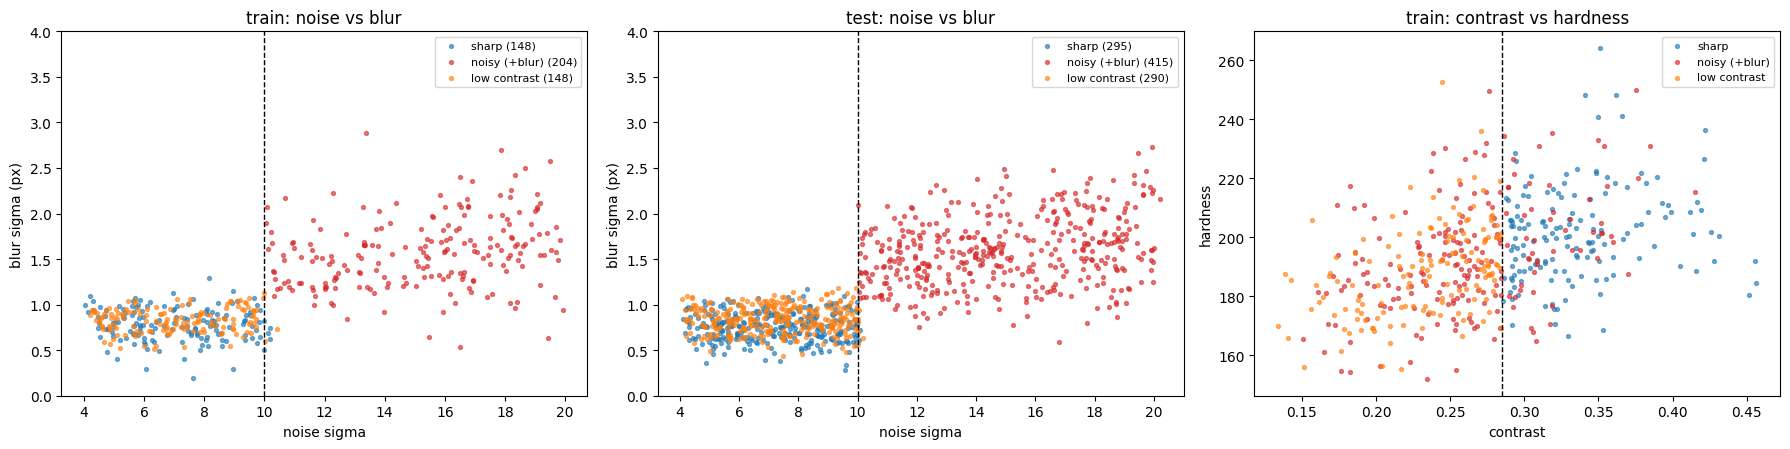

In [ ]:
COL = {'sharp': 'tab:blue', 'noisy': 'tab:red', 'lowcon': 'tab:orange'}
fig, axes = plt.subplots(1, 3, figsize=(18, 4.6))
for ax, Q, G, t in ((axes[0], Q_tr, GROUP_TR, 'train'), (axes[1], Q_te, GROUP_TE, 'test')):
    for g in GROUP_CODES:
        m = G == g
        ax.scatter(Q['noise'].to_numpy()[m], Q['blur'].to_numpy()[m], s=8, alpha=0.6, c=COL[g], label=f'{GROUP_EN[g]} ({m.sum()})')
    ax.axvline(GROUP_NOISE_SIGMA, color='k', ls='--', lw=1)
    ax.set_ylim(0, 4)
    ax.set_xlabel('noise sigma')
    ax.set_ylabel('blur sigma (px)')
    ax.set_title(f'{t}: noise vs blur')
    ax.legend(fontsize=8)
for g in GROUP_CODES:
    m = GROUP_TR == g
    axes[2].scatter(Q_tr['contrast'].to_numpy()[m], y[m], s=8, alpha=0.6, c=COL[g], label=GROUP_EN[g])
axes[2].axvline(CONTRAST_THR, color='k', ls='--', lw=1)
axes[2].set_xlabel('contrast')
axes[2].set_ylabel('hardness')
axes[2].set_title('train: contrast vs hardness')
axes[2].legend(fontsize=8)
plt.tight_layout()
plt.show()

## 3. 학습/검증 분할
- **원안 (400/100)**: 한 번 나눠 참고용으로 같이 보여줍니다. **세 묶음 각각을 4:1로** 나누고, 묶음 안에서도 경도 구간이 고르게 들어가도록 층화합니다 (`STRATIFY_GROUPS = True`).
- **보완 (5-fold × 3회 반복)**: 100장 한 번으로 매긴 점수는 어떤 100장이 뽑혔느냐에 따라 크게 흔들립니다. 500장을 5등분해 돌아가며 검증하고, 이를 다른 분할로 3번 반복해 평균을 내면 모델 비교가 훨씬 안정적입니다. 각 fold에도 세 묶음 × 경도 구간이 고르게 들어갑니다.
- 비교가 끝나면 최종 모델은 **500장 전부**로 다시 학습합니다 (검증용 100장을 버리지 않음).

In [ ]:
idx_all = np.arange(len(y))

def make_strata(n_bins):
    """층화 기준: 경도 구간 (STRATIFY_GROUPS 이면 묶음 × 경도 구간)"""
    b = pd.Series(pd.qcut(y, q=n_bins, labels=False, duplicates='drop')).astype(str)
    return (pd.Series(GROUP_TR).astype(str) + '_' + b).to_numpy() if STRATIFY_GROUPS else b.to_numpy()

try:
    idx_tr, idx_va = train_test_split(idx_all, test_size=0.2, random_state=SEED,
                                      stratify=make_strata(5 if STRATIFY_GROUPS else 10))
except ValueError:
    idx_tr, idx_va = train_test_split(idx_all, test_size=0.2, random_state=SEED)
print(f'(원안) 홀드아웃: 학습 {len(idx_tr)}장 / 검증 {len(idx_va)}장')
print('       묶음별 학습/검증: ' + ', '.join(f'{GROUP_KO[g]} {np.sum(GROUP_TR[idx_tr] == g)}/{np.sum(GROUP_TR[idx_va] == g)}'
                                       for g in GROUP_CODES))

CV_SPLITS = None
if STRATIFY_GROUPS:
    try:
        CV_SPLITS = list(RepeatedStratifiedKFold(n_splits=N_FOLDS, n_repeats=N_REPEATS, random_state=SEED)
                         .split(idx_all, make_strata(3)))
    except ValueError:
        CV_SPLITS = None
if CV_SPLITS is None:
    CV_SPLITS = list(RepeatedKFold(n_splits=N_FOLDS, n_repeats=N_REPEATS, random_state=SEED).split(idx_all))
SPLIT_TAG = hashlib.md5(np.concatenate([va for _, va in CV_SPLITS]).astype(np.int64).tobytes()).hexdigest()[:8]
print(f'(보완) 교차검증: {N_FOLDS}-fold × {N_REPEATS}회 = 학습/검증 {len(CV_SPLITS)}번'
      + (' (묶음 × 경도 구간으로 층화)' if STRATIFY_GROUPS else ''))
print('       첫 fold 검증 이미지의 묶음 구성: ' + ', '.join(f'{GROUP_KO[g]} {np.sum(GROUP_TR[CV_SPLITS[0][1]] == g)}'
                                                for g in GROUP_CODES))

(원안) 홀드아웃: 학습 400장 / 검증 100장
       묶음별 학습/검증: 선명 118/30, 잡음 많음 163/41, 대비 낮음 119/29
(보완) 교차검증: 5-fold × 3회 = 학습/검증 15번 (묶음 × 경도 구간으로 층화)
       첫 fold 검증 이미지의 묶음 구성: 선명 29, 잡음 많음 42, 대비 낮음 29


## 4. 조건별 지표 (K) — 설명서의 5가지 조건을 직접 측정
이미지마다 노이즈·흐림·밝기가 크게 달라서, 먼저 노이즈를 걷어낸 **결정립 지도**(스무딩 후 얇은 결정립계 선을 지운 이미지)를 만들고 그 위에서 잽니다. 기공은 먼저 찾아서 2상·결정립 측정에서 제외합니다. 지표 이름의 앞자리가 조건 번호입니다.

| 조건 | 지표 (이름) | 측정 방법 |
|---|---|---|
| 1 결정립 크기 | `c1_corr_len`, `c1_hallpetch`, `c1_spec_*`, `c1_boundary_density`, `c1_edge_density` | 결정립 지도의 자기상관 길이(명암이 바뀌는 평균 간격)와 그 d^(-1/2), 스펙트럼 주기, 결정립계 선·명암 경계의 밀도 |
| 2 2상 | `c2_iqr_rel`, `c2_std_rel`, `c2_dark_tail_rel`, `c2_asym`, `c2_dark_frac_*` | 기공을 뺀 결정립 지도의 명암 퍼짐(중앙값 대비)과 어두운 쪽 꼬리, 밝은 쪽 대비 어두운 쪽 비대칭 |
| 3 기공 | `c3_pore_frac`, `c3_pore_count`, `c3_pore_*_area` | 중앙 밝기의 70%보다 어두운 작은 덩어리의 면적 비율·개수·크기 |
| 4 균일성 | `c4_tile_boundary_cv`, `c4_tile_edge_cv`, `c4_tile_mean_cv` | 이미지를 4×4 구역으로 나눠 결정립계 밀도·명암이 구역마다 얼마나 다른지 |
| 5 신장 | `c5_corr_ar`, `c5_coherence_*`, `c5_global_align` | 한 점 기준 자기상관 영역의 장축/단축 비, 구조 텐서 정렬도 (방향 자체는 쓰지 않음) |
| 촬영 조건 | `img_noise`, `img_median`, `img_snr` | 노이즈 크기, 밝기, 구조 신호 대 노이즈 비 |

이미지당 약 0.1초이며, 결과는 캐시에 저장됩니다.

In [ ]:
# ---------- 조건별 지표 ----------
_KR = np.rint(np.sqrt((np.fft.fftfreq(256) * 256)[:, None] ** 2 + (np.fft.fftfreq(256) * 256)[None, :] ** 2)).astype(int)

def _radial(P):
    """2차원 파워 스펙트럼 → 반지름(주파수)별 평균"""
    s = np.bincount(_KR.ravel(), P.ravel(), minlength=182)
    n = np.bincount(_KR.ravel(), minlength=182)
    return (s / np.maximum(n, 1))[:129]

def _acf_shape(field, level):
    """자기상관이 level 이상인 중앙 영역 → (크기 √면적, 장축/단축 비)"""
    c = np.fft.fftshift(np.fft.ifft2(np.abs(np.fft.fft2(field - field.mean())) ** 2).real)
    c /= c.max() + 1e-12
    cy, cx = np.array(c.shape) // 2
    lab, _ = ndi.label(c > level)
    yy, xx = np.nonzero(lab == lab[cy, cx])
    if len(yy) < 3:
        return 1.0, 1.0
    ev = np.sort(np.clip(np.linalg.eigvalsh(np.cov(np.vstack([xx - cx, yy - cy]))), 1e-6, None))[::-1]
    return float(np.sqrt(len(yy))), float(np.sqrt(ev[0] / ev[1]))

def condition_features(img):
    x = img.astype(np.float32)
    f = {}
    # 촬영 조건 (경도 요인이 아니라 측정을 왜곡하는 요인)
    lap = ndi.convolve(x, np.array([[1, -2, 1], [-2, 4, -2], [1, -2, 1]], np.float32))
    noise = np.sqrt(np.pi / 2) * np.abs(lap[1:-1, 1:-1]).mean() / 6.0
    s1 = ndi.gaussian_filter(x, 1.0)
    s = ndi.gaussian_filter(x, 1.5)
    g = ndi.grey_opening(ndi.grey_closing(s, footprint=disk(2)), footprint=disk(1))   # 결정립계 선을 지운 결정립 지도
    med = float(np.median(g))
    r = _radial(np.abs(np.fft.fft2(x - x.mean())) ** 2)
    floor = r[110:128].mean()                                          # 고주파 = 노이즈 바닥
    sig = np.clip(r - floor, 1e-9, None)
    f['img_noise'] = noise
    f['img_median'] = med
    f['img_snr'] = np.log(sig[2:6].mean() / floor)
    # 조건 3: 기공 = 중앙 밝기의 70%보다 어두운 작은 덩어리
    pore = ndi.binary_opening(s < 0.7 * med, structure=disk(1))
    lab, n = ndi.label(pore)
    areas = np.bincount(lab.ravel())[1:] if n else np.zeros(1)
    f['c3_pore_frac'] = pore.mean()
    f['c3_pore_count'] = np.log1p(n)
    f['c3_pore_mean_area'] = areas.mean() if n else 0.0
    f['c3_pore_max_area'] = areas.max() if n else 0.0
    pore_d = ndi.binary_dilation(pore, structure=disk(3))
    gv = g[~pore_d]
    # 조건 2: 2상 = 어두운 결정립 (기공·결정립계 선 제외)
    p = np.percentile(gv, [10, 25, 50, 75, 90])
    upper = p[4] - p[2] + 1e-6                                         # 밝은 쪽(기지) 퍼짐
    f['c2_iqr_rel'] = (p[3] - p[1]) / p[2]
    f['c2_std_rel'] = gv.std() / p[2]
    f['c2_dark_tail_rel'] = (p[2] - p[0]) / p[2]
    f['c2_asym'] = (p[2] - p[0]) / upper
    for k in (1.5, 2.0, 3.0):
        f[f'c2_dark_frac_{k}'] = np.mean(gv < p[2] - k * upper)
    # 조건 1: 결정립 크기 = 명암이 바뀌는 평균 간격 (자기상관 길이, 스펙트럼 주기, 경계 밀도)
    gh = g - ndi.gaussian_filter(g, 16)
    gh[pore_d] = 0
    for lev in (0.5, 0.25):
        size, ar = _acf_shape(gh, lev)
        f[f'c1_corr_len_{int(lev * 100)}'] = size
        f[f'c1_hallpetch_{int(lev * 100)}'] = size ** -0.5             # Hall-Petch: d^(-1/2)
        f[f'c5_corr_ar_{int(lev * 100)}'] = ar                         # 조건 5: 1 = 둥글게, 클수록 길쭉
    low = sig[2:6].mean()
    below = np.nonzero(sig[2:] < 0.05 * low)[0]
    f['c1_spec_knee_period'] = 256 / (2 + below[0]) if len(below) else 2.0
    kk = np.arange(len(sig))
    w = sig[2:110] * kk[2:110]
    f['c1_spec_mean_period'] = 256 / (np.sum(w * kk[2:110]) / np.sum(w))
    bth = ndi.grey_closing(s1, footprint=disk(2)) - s1                 # 얇고 어두운 선 = 결정립계
    bth[pore_d] = 0
    bmask = bth > max(3.0 * noise / np.sqrt(4 * np.pi), 2.0)
    f['c1_boundary_density'] = bmask.mean()
    gy, gx = np.gradient(g)
    gm = np.hypot(gx, gy)
    gm[pore_d] = 0
    for k in (1.0, 2.0):
        f[f'c1_edge_density_{k}'] = np.mean(gm > k * (gv.std() + 1e-6) / 4)
    # 조건 5: 신장·정렬 정도 (구조 텐서, 방향 자체는 쓰지 않음)
    sy, sx = np.gradient(s)
    for rho in (4, 8, 16):
        jxx, jyy, jxy = (ndi.gaussian_filter(q, rho) for q in (sx * sx, sy * sy, sx * sy))
        f[f'c5_coherence_{rho}'] = float(np.mean(np.sqrt((jxx - jyy) ** 2 + 4 * jxy ** 2) / (jxx + jyy + 1e-6)))
    Jxx, Jyy, Jxy = (sx * sx).mean(), (sy * sy).mean(), (sx * sy).mean()
    f['c5_global_align'] = float(np.sqrt((Jxx - Jyy) ** 2 + 4 * Jxy ** 2) / (Jxx + Jyy + 1e-6))
    # 조건 4: 크기·공간 균일성 = 4x4 구역별 결정립계 밀도·명암 차이
    tb = bmask.reshape(4, 64, 4, 64).mean(axis=(1, 3))
    te = gm.reshape(4, 64, 4, 64).mean(axis=(1, 3))
    tm = g.reshape(4, 64, 4, 64).mean(axis=(1, 3))
    f['c4_tile_boundary_cv'] = tb.std() / (tb.mean() + 1e-6)
    f['c4_tile_edge_cv'] = te.std() / (te.mean() + 1e-6)
    f['c4_tile_mean_cv'] = tm.std() / med
    return {k: float(v) for k, v in f.items()}

K_tr, K_te = clean(features_cached(condition_features, X_tr_img, 'train', 'cond_v1'),
                   features_cached(condition_features, X_te_img, 'test', 'cond_v1'))
F_K_tr, F_K_te = K_tr.to_numpy(np.float64), K_te.to_numpy(np.float64)
print(f'조건 지표 K: {F_K_tr.shape[1]}개 / 이미지')

cond_v1 train: 500장 → 32개 (7s)
cond_v1 test: 1000장 → 32개 (14s)
조건 지표 K: 32개 / 이미지


## 5. 조건 검증 — 학습 데이터로 방향과 세기 확인
조건마다 대표 지표 하나를 골라 세 가지를 봅니다.

- **단독 상관 r**: 그 지표 하나만 봤을 때의 경향. 다른 조건과 섞여 있어 착시가 생길 수 있습니다.
- **다른 조건 고정 시 효과**: 대표 지표 5개를 함께 넣은 선형 회귀의 계수(표준편차 1만큼 커질 때 경도 변화, HV)와 95% 구간. 구간이 0을 넘지 않으면 방향이 분명하다고 판정합니다. 설명서가 "한 가지 특징만으로 증감을 단정할 수 없다"고 한 부분을 이렇게 확인합니다.
- **빼면 RMSE 변화**: K에서 그 조건의 지표를 모두 빼고 교차검증했을 때 RMSE가 얼마나 나빠지는지. 클수록 다른 조건으로 대신할 수 없는 정보입니다.

,단독 상관 r,다른 조건 고정 시 효과 (HV),95% 구간,판정,빼면 RMSE 변화
조건,,,,,
조건1 결정립 크기 (클수록 조대),0.45,3.10,"[1.2, 5.0]",경도 ↑,0.13
조건2 2상 (어두운 결정립),0.57,8.31,"[6.9, 9.7]",경도 ↑,0.68
조건3 기공 (면적 비율),0.06,-1.22,"[-2.5, 0.0]",뚜렷하지 않음,0.06
조건4 크기 불균일 (구역별 편차),0.03,0.97,"[-0.7, 2.6]",뚜렷하지 않음,-0.03
"조건5 신장 (정렬도, 0=둥글게)",0.35,2.63,"[0.9, 4.4]",경도 ↑,0.03


교차검증 RMSE: 조건 지표 전체 K (32개) 13.968 | 대표 지표 5개만 13.878 | 기준선(평균으로 예측) 17.680


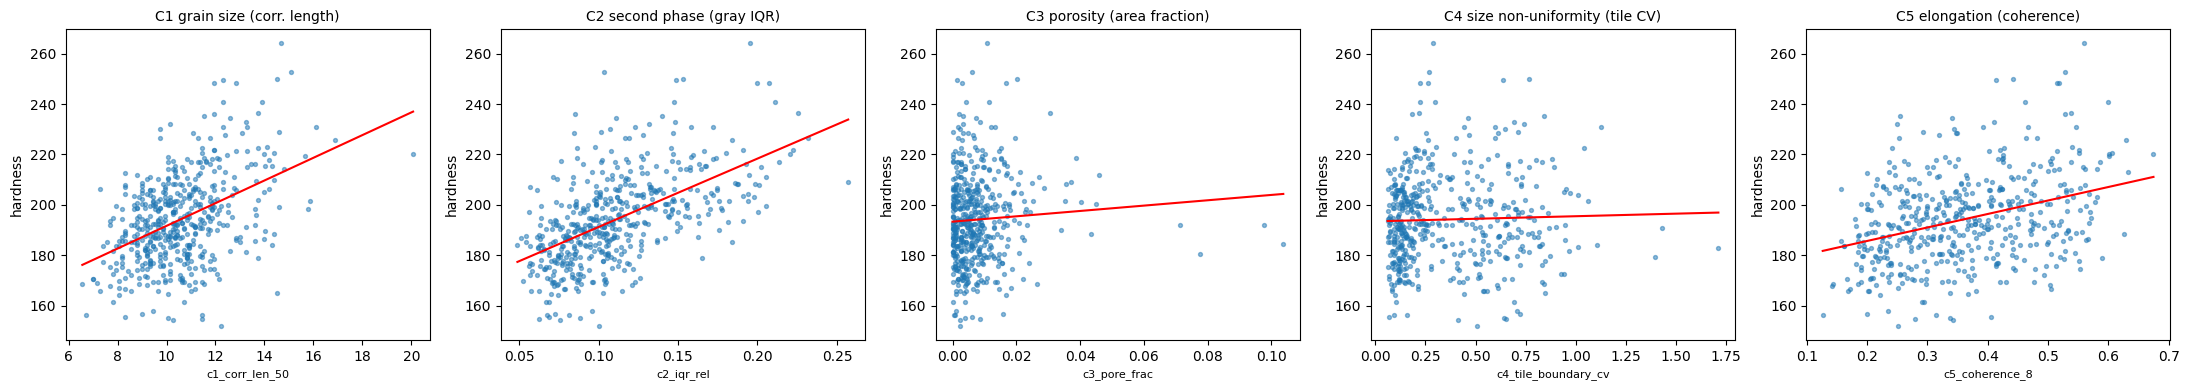

In [ ]:
COND = {                                                   # 조건별 대표 지표
    '조건1 결정립 크기 (클수록 조대)': 'c1_corr_len_50',
    '조건2 2상 (어두운 결정립)': 'c2_iqr_rel',
    '조건3 기공 (면적 비율)': 'c3_pore_frac',
    '조건4 크기 불균일 (구역별 편차)': 'c4_tile_boundary_cv',
    '조건5 신장 (정렬도, 0=둥글게)': 'c5_coherence_8',
}
rep = list(COND.values())
Z = StandardScaler().fit_transform(K_tr[rep].to_numpy(np.float64))
Xd = np.c_[np.ones(len(y)), Z]
beta, *_ = np.linalg.lstsq(Xd, y, rcond=None)
resid = y - Xd @ beta
se = np.sqrt(np.diag(resid @ resid / (len(y) - Xd.shape[1]) * np.linalg.inv(Xd.T @ Xd)))

base_rmse = cv_rmse(F_K_tr)
rows = []
for i, ((name, col), b, e) in enumerate(zip(COND.items(), beta[1:], se[1:]), start=1):
    lo, hi = b - 1.96 * e, b + 1.96 * e
    group = [c for c in K_tr.columns if c.startswith(f'c{i}_')]
    rows.append({'조건': name,
                 '단독 상관 r': np.corrcoef(K_tr[col], y)[0, 1],
                 '다른 조건 고정 시 효과 (HV)': b,
                 '95% 구간': f'[{lo:.1f}, {hi:.1f}]',
                 '판정': '경도 ↑' if lo > 0 else ('경도 ↓' if hi < 0 else '뚜렷하지 않음'),
                 '빼면 RMSE 변화': cv_rmse(K_tr.drop(columns=group)) - base_rmse})
cond_table = pd.DataFrame(rows).set_index('조건')
display(cond_table.round(2))
print(f'교차검증 RMSE: 조건 지표 전체 K ({F_K_tr.shape[1]}개) {base_rmse:.3f} | 대표 지표 5개만 {cv_rmse(K_tr[rep]):.3f} '
      f'| 기준선(평균으로 예측) {y.std():.3f}')

titles = ['C1 grain size (corr. length)', 'C2 second phase (gray IQR)', 'C3 porosity (area fraction)',
          'C4 size non-uniformity (tile CV)', 'C5 elongation (coherence)']
fig, axes = plt.subplots(1, 5, figsize=(22, 4))
for ax, col, t in zip(axes, rep, titles):
    xv = K_tr[col].to_numpy(np.float64)
    ax.scatter(xv, y, s=8, alpha=0.5)
    slope, icpt = np.polyfit(xv, y, 1)
    xs = np.linspace(xv.min(), xv.max(), 50)
    ax.plot(xs, slope * xs + icpt, 'r-', lw=1.5)
    ax.set_title(t, fontsize=10)
    ax.set_xlabel(col, fontsize=8)
    ax.set_ylabel('hardness')
plt.tight_layout()
plt.show()

## 5-1. 묶음별 조건 태그 — 결정립 크기 · 어두운 상 · 기공 · 정렬
4단계 지표로 이미지마다 네 가지 태그를 3단계로 붙이고, 묶음마다 어떤 미세구조가 많은지 요약합니다.

| 태그 | 지표 | 3단계 |
|---|---|---|
| 결정립 크기 | `c1_corr_len_50` (명암이 바뀌는 평균 간격, 픽셀) | 미세 / 보통 / 조대 |
| 어두운 상 | `c2_iqr_rel` (기공을 뺀 결정립 지도의 명암 퍼짐) | 적음 / 보통 / 많음 |
| 기공 | `c3_pore_frac` (아주 어두운 작은 덩어리의 면적 비율) | 적음 / 보통 / 많음 |
| 정렬 | `c5_corr_ar_50` (자기상관 영역의 장축/단축 비) | 등축 / 약함 / 강함 |

잡음 이미지에서는 같은 미세구조라도 결정립계·2상이 덜 잡혀 값이 한쪽으로 치우칩니다. 그래서 **깨끗한 이미지와 잡음 이미지를 따로 3등분**합니다 (경도는 쓰지 않음). 묶음·태그·촬영 상태 값은 `groups_tags_train.csv`, `groups_tags_test.csv`로 저장됩니다.

In [ ]:
TAGS = {   # 태그: (4단계 지표, 낮음 → 높음 3단계 이름)
    '결정립 크기': ('c1_corr_len_50', ('미세', '보통', '조대')),
    '어두운 상': ('c2_iqr_rel', ('적음', '보통', '많음')),
    '기공': ('c3_pore_frac', ('적음', '보통', '많음')),
    '정렬': ('c5_corr_ar_50', ('등축', '약함', '강함')),
}
TAG_EN = {'미세': 'fine', '보통': 'mid', '조대': 'coarse', '적음': 'low', '많음': 'high',
          '등축': 'equiaxed', '약함': 'weak', '강함': 'strong'}

def make_tags(Kdf_tr, Kdf_te):
    """깨끗한 이미지 / 잡음 이미지를 따로, 학습+예측 이미지 전체 기준으로 3등분"""
    T_tr, T_te = pd.DataFrame(index=range(len(Kdf_tr))), pd.DataFrame(index=range(len(Kdf_te)))
    for name, (col, labels) in TAGS.items():
        v_tr, v_te = Kdf_tr[col].to_numpy(np.float64), Kdf_te[col].to_numpy(np.float64)
        a_tr, a_te = np.full(len(v_tr), labels[1], dtype=object), np.full(len(v_te), labels[1], dtype=object)
        for r in (False, True):
            m_tr, m_te = NOISY_TR == r, NOISY_TE == r
            ref = np.r_[v_tr[m_tr], v_te[m_te]]
            if len(ref) == 0:
                continue
            q1, q2 = np.quantile(ref, [1 / 3, 2 / 3])
            for a, v, m in ((a_tr, v_tr, m_tr), (a_te, v_te, m_te)):
                a[m] = np.where(v[m] < q1, labels[0], np.where(v[m] < q2, labels[1], labels[2]))
        T_tr[name], T_te[name] = a_tr, a_te
    return T_tr, T_te

TAG_TR, TAG_TE = make_tags(K_tr, K_te)

rows = []
for g in GROUP_CODES:
    m = GROUP_TR == g
    if not m.any():
        continue
    row = {'묶음': GROUP_KO[g], '학습 (장)': int(m.sum()),
           '경도 평균': y[m].mean(), '경도 범위': f'{y[m].min():.0f} ~ {y[m].max():.0f}',
           '결정립 크기 (px)': K_tr['c1_corr_len_50'][m].median(),
           '어두운 상 퍼짐': K_tr['c2_iqr_rel'][m].median(),
           '기공 면적 (%)': 100 * K_tr['c3_pore_frac'][m].median(),
           '정렬 (장/단축비)': K_tr['c5_corr_ar_50'][m].median()}
    for name, (_, labels) in TAGS.items():
        row[f'{name} {labels[2]} 비율 (%)'] = 100 * np.mean(TAG_TR[name].to_numpy()[m] == labels[2])
    rows.append(row)
print('묶음별 요약 (지표는 중앙값):')
display(pd.DataFrame(rows).set_index('묶음').round(2).T)

tab = {}
for name, (_, labels) in TAGS.items():
    for lab in labels:
        sel = TAG_TR[name].to_numpy() == lab
        tab[(name, lab)] = {'깨끗한 이미지': y[sel & ~NOISY_TR].mean() if (sel & ~NOISY_TR).any() else np.nan,
                            '잡음 이미지': y[sel & NOISY_TR].mean() if (sel & NOISY_TR).any() else np.nan,
                            '학습 (장)': int(sel.sum())}
print('태그별 평균 경도 (같은 태그면 촬영 상태와 상관없이 비슷해야 태그가 미세구조를 제대로 잡은 것):')
display(pd.DataFrame.from_dict(tab, orient='index').round(1))

out_tr = pd.concat([pd.DataFrame({'ID': train_ids, 'hardness': y, '묶음': [GROUP_KO[g] for g in GROUP_TR]}),
                    Q_tr.round(3), TAG_TR], axis=1)
out_te = pd.concat([pd.DataFrame({'ID': test_ids, '묶음': [GROUP_KO[g] for g in GROUP_TE]}), Q_te.round(3), TAG_TE], axis=1)
TAG_FILES = [DATA_DIR / 'groups_tags_train.csv', DATA_DIR / 'groups_tags_test.csv']
out_tr.to_csv(TAG_FILES[0], index=False, encoding='utf-8-sig')
out_te.to_csv(TAG_FILES[1], index=False, encoding='utf-8-sig')
print(f'묶음·태그 저장: {TAG_FILES[0]} , {TAG_FILES[1]}')

묶음별 요약 (지표는 중앙값):


묶음,선명,잡음 많음,대비 낮음
학습 (장),148,204,148
경도 평균,201.28,193.31,188.22
경도 범위,166 ~ 264,152 ~ 250,155 ~ 253
결정립 크기 (px),10.63,10.72,9.64
어두운 상 퍼짐,0.14,0.1,0.08
기공 면적 (%),0.98,0.41,0.44
정렬 (장/단축비),1.68,1.59,1.54
결정립 크기 조대 비율 (%),46.62,36.76,19.59
어두운 상 많음 비율 (%),62.16,30.39,8.11
기공 많음 비율 (%),49.32,31.37,13.51


태그별 평균 경도 (같은 태그면 촬영 상태와 상관없이 비슷해야 태그가 미세구조를 제대로 잡은 것):


깨끗한 이미지  잡음 이미지  학습 (장)
결정립 크기 미세    186.7   185.8     151
       보통    194.2   188.8     176
       조대    203.3   203.2     173
어두운 상  적음    181.5   185.8     168
       보통    193.8   192.0     166
       많음    207.6   203.8     166
기공     적음    192.4   192.8     179
       보통    193.3   195.0     164
       많음    198.8   192.3     157
정렬     등축    188.6   186.3     170
       약함    194.9   191.5     161
       강함    201.5   200.7     169

묶음·태그 저장: /content/data/groups_tags_train.csv , /content/data/groups_tags_test.csv


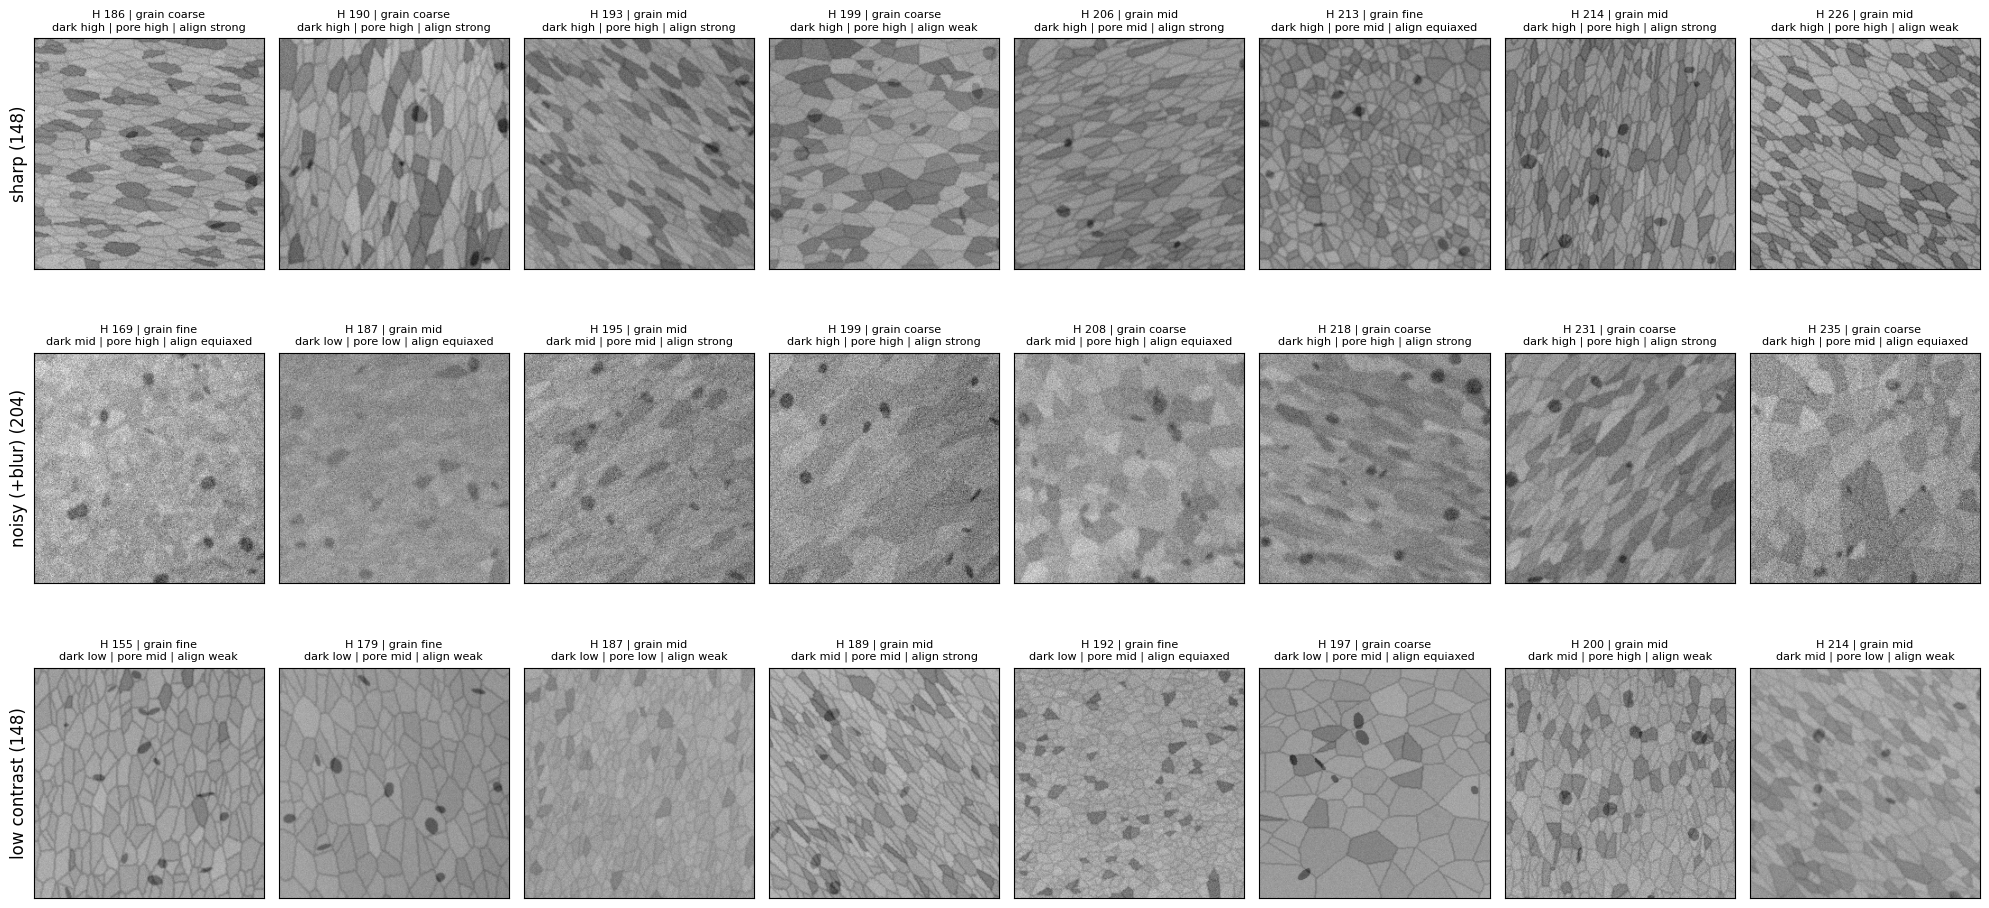

In [ ]:
# 묶음마다 무작위 8장 (경도 순), 제목 = 경도 | 태그
rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(len(GROUP_CODES), 8, figsize=(20, 3.3 * len(GROUP_CODES)), squeeze=False)
for r, g in enumerate(GROUP_CODES):
    pool = np.nonzero(GROUP_TR == g)[0]
    pick = sorted(rng.choice(pool, min(8, len(pool)), replace=False), key=lambda i: y[i]) if len(pool) else []
    for c in range(8):
        ax = axes[r, c]
        ax.set_xticks([])
        ax.set_yticks([])
        if c == 0:
            ax.set_ylabel(f'{GROUP_EN[g]} ({len(pool)})', fontsize=12)
        if c >= len(pick):
            ax.set_frame_on(False)
            continue
        i, t = pick[c], TAG_TR.iloc[pick[c]]
        ax.imshow(X_tr_img[i], cmap='gray', vmin=0, vmax=255)
        ax.set_title(f'H {y[i]:.0f} | grain {TAG_EN[t["결정립 크기"]]}\n'
                     f'dark {TAG_EN[t["어두운 상"]]} | pore {TAG_EN[t["기공"]]} | align {TAG_EN[t["정렬"]]}', fontsize=8)
plt.tight_layout()
plt.show()

## 6. ResNet18 특징 추출
ImageNet으로 사전학습된 ResNet18을 **고정(frozen)** 한 채 특징만 뽑습니다. 500장으로 CNN 전체를 다시 학습하면 과적합되기 쉬우므로 '고정 특징 + Ridge'라는 원안의 선택은 적절합니다. 다만 다음을 보완합니다.

- 흑백 1채널 → 3채널 복제, `/255` 후 ImageNet 평균·표준편차로 정규화 (사전학습 때와 같은 입력 조건)
- **A (원안)**: 마지막 층(layer4) 전역 평균 → 512개
- **B (개선)**: layer1~4 각각의 채널 평균 + 표준편차 → 1920개. 결정립 크기·경계 같은 '질감' 정보는 마지막 층보다 중간 층에 더 많이 남아 있습니다.
- **TTA**: 미세구조는 돌리거나 뒤집어도 경도가 같으므로, 8방향(90° 회전 4 × 좌우반전 2)의 특징을 평균해 방향에 따른 흔들림을 줄입니다.
- 계산 결과는 `feature_cache` 폴더에 저장되어 다시 실행하면 바로 불러옵니다.

In [ ]:
cnn = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1).to(DEVICE).eval()   # 사전학습 가중치, 학습하지 않음
MEAN = torch.tensor([0.485, 0.456, 0.406], device=DEVICE).view(1, 3, 1, 1)
STD  = torch.tensor([0.229, 0.224, 0.225], device=DEVICE).view(1, 3, 1, 1)

@torch.no_grad()
def resnet_feats(x):
    """x: (B,3,H,W) → (layer4 평균 512개, layer1~4 평균+표준편차 1920개)"""
    h = cnn.maxpool(cnn.relu(cnn.bn1(cnn.conv1(x))))
    pooled = []
    for layer in (cnn.layer1, cnn.layer2, cnn.layer3, cnn.layer4):
        h = layer(h)
        pooled += [h.mean(dim=(2, 3)), h.std(dim=(2, 3))]
    return pooled[-2], torch.cat(pooled, dim=1)

@torch.no_grad()
def extract_resnet(imgs, tta=True, batch_size=32):
    views = [(k, flip) for k in range(4) for flip in (False, True)] if tta else [(0, False)]
    base_all, multi_all = [], []
    for i in range(0, len(imgs), batch_size):
        x = torch.from_numpy(imgs[i:i + batch_size]).float().div(255.0)    # (B,256,256), 0~1
        x = x.unsqueeze(1).repeat(1, 3, 1, 1).to(DEVICE)                   # 흑백 → 3채널
        x = (x - MEAN) / STD                                               # ImageNet 정규화
        multi_sum = 0
        for k, flip in views:
            v = torch.rot90(x, k, dims=(2, 3))
            if flip:
                v = torch.flip(v, dims=(3,))
            base, multi = resnet_feats(v)
            if k == 0 and not flip:
                base_all.append(base.cpu().numpy())                       # A: 원본 방향만
            multi_sum = multi_sum + multi
        multi_all.append((multi_sum / len(views)).cpu().numpy())           # B: 8방향 평균
    return np.concatenate(base_all), np.concatenate(multi_all)

def resnet_cached(imgs, name):
    f = CACHE_DIR / f'resnet_{name}_{data_key(imgs)}_tta{int(USE_TTA)}.npz'
    if f.exists():
        d = np.load(f)
        print(f'{name}: 캐시 사용 ({f.name})')
        return d['base'], d['multi']
    t0 = time.time()
    base, multi = extract_resnet(imgs, tta=USE_TTA, batch_size=BATCH_SIZE)
    np.savez(f, base=base, multi=multi)
    print(f'{name}: {len(imgs)}장 → A {base.shape[1]}개 / B {multi.shape[1]}개 특징 ({time.time() - t0:.0f}s)')
    return base, multi

F_A_tr, F_B_tr = resnet_cached(X_tr_img, 'train')
F_A_te, F_B_te = resnet_cached(X_te_img, 'test')

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 220MB/s]


train: 500장 → A 512개 / B 1920개 특징 (3s)
test: 1000장 → A 512개 / B 1920개 특징 (2s)


## 6-1. 다른 CNN 특징 (EN·VG)
ResNet18(B)과 같은 방식으로, ImageNet으로 사전학습된 다른 CNN 두 개의 특징을 고정한 채 뽑아 비교합니다.

- **EN (EfficientNet-B0)**: 2019년 모델. ResNet18보다 작지만(파라미터 530만 개) ImageNet 정확도는 더 높습니다. 단계 9개 각각의 채널 평균 + 표준편차를 씁니다.
- **VG (VGG-16)**: 2014년 모델로 오래됐지만, 층별 특징의 평균·표준편차가 그림의 질감·화풍을 잘 담는 것으로 알려져 있습니다 (스타일 전이 연구에서 쓰는 방식). 미세구조 이미지는 질감에 가까워서 넣어 봅니다. 블록 5개의 마지막 출력을 씁니다.
- 입력·정규화·TTA는 ResNet과 같습니다 (256×256 그대로, 8방향 평균). GPU에서만 자동 실행되며 결과는 캐시됩니다. 불러오지 못한 모델은 건너뜁니다.
- 9단계 최종 선택의 "CNN 특징" 대표는 A·B·EN·VG 중 교차검증이 가장 좋은 것으로 자동으로 바뀝니다. 두 모델은 미세조정 F의 백본으로도 고를 수 있습니다 (`FT_BACKBONE`).

In [ ]:
import gc

CNN_NAMES = {'efficientnet_b0': ('EN', 'EfficientNet-B0 단계 9개 평균·표준편차'),
             'vgg16': ('VG', 'VGG-16 블록 5개 평균·표준편차')}
CNN_FEATS = {}                                          # 키 → (설명, 학습 특징, 예측 특징)

def load_stage_cnn(name):
    """→ (단계별로 이어진 층 목록, 특징을 뽑을 층 번호)"""
    if name == 'efficientnet_b0':
        net = efficientnet_b0(weights=EfficientNet_B0_Weights.IMAGENET1K_V1).features
        take = list(range(len(net)))                    # 단계 9개 전부
    elif name == 'vgg16':
        net = vgg16(weights=VGG16_Weights.IMAGENET1K_V1).features
        take = [3, 8, 15, 22, 29]                       # 블록 1~5 마지막 ReLU 출력
    else:
        raise ValueError(f'지원하지 않는 CNN: {name}')
    return net.to(DEVICE).eval(), take

@torch.no_grad()
def extract_stage_stats(imgs, net, take, tta=True, batch_size=32):
    """층마다 채널 평균 + 표준편차, TTA 면 8방향 평균"""
    views = [(k, flip) for k in range(4) for flip in (False, True)] if tta else [(0, False)]
    amp = DEVICE == 'cuda'
    out = []
    for i in range(0, len(imgs), batch_size):
        x = torch.from_numpy(imgs[i:i + batch_size]).float().div(255.0)
        x = (x.unsqueeze(1).repeat(1, 3, 1, 1).to(DEVICE) - MEAN) / STD
        acc = 0
        for k, flip in views:
            h = torch.rot90(x, k, dims=(2, 3))
            if flip:
                h = torch.flip(h, dims=(3,))
            pooled = []
            with torch.autocast(device_type='cuda' if amp else 'cpu', enabled=amp):
                for j, layer in enumerate(net):
                    h = layer(h)
                    if j in take:
                        hf = h.float()
                        pooled += [hf.mean(dim=(2, 3)), hf.std(dim=(2, 3))]
                    if j >= take[-1]:
                        break
            acc = acc + torch.cat(pooled, dim=1)
        out.append((acc / len(views)).cpu().numpy())
    return np.concatenate(out)

def stage_cnn_features(name):
    """학습·예측 이미지의 특징. 캐시가 있으면 모델을 불러오지 않음"""
    files = {s: CACHE_DIR / f'cnn_{name}_{s}_{data_key(im)}_tta{int(USE_TTA)}.npz'
             for s, im in (('train', X_tr_img), ('test', X_te_img))}
    if all(f.exists() for f in files.values()):
        print(f'{name}: 캐시 사용')
        return np.load(files['train'])['feat'], np.load(files['test'])['feat']
    t0 = time.time()
    net, take = load_stage_cnn(name)
    feats = {}
    for s, im in (('train', X_tr_img), ('test', X_te_img)):
        feats[s] = extract_stage_stats(im, net, take, tta=USE_TTA, batch_size=BATCH_SIZE)
        if not np.isfinite(feats[s]).all():
            raise RuntimeError('특징에 NaN/inf 가 생겼습니다')
        np.savez(files[s], feat=feats[s])
    print(f'{name}: 특징 {feats["train"].shape[1]}개 ({time.time() - t0:.0f}s)')
    return feats['train'], feats['test']

run_cnns = (DEVICE == 'cuda') if RUN_CNNS == 'auto' else bool(RUN_CNNS)
if run_cnns:
    for name in EXTRA_CNNS:
        try:
            key, desc = CNN_NAMES[name]
            tr_f, te_f = stage_cnn_features(name)
            CNN_FEATS[key] = (desc, tr_f, te_f)
        except Exception as e:
            print(f'※ {name} 특징을 만들지 못해 건너뜁니다 ({type(e).__name__}: {str(e)[:200]})')
    gc.collect()
    if DEVICE == 'cuda':
        torch.cuda.empty_cache()
else:
    print('다른 CNN 특징(EN·VG)을 건너뜁니다. GPU 런타임에서 실행하거나 설정 셀의 RUN_CNNS 를 바꾸세요.')

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 158MB/s]


efficientnet_b0: 특징 4192개 (9s)
Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:02<00:00, 220MB/s]


vgg16: 특징 2944개 (11s)


## 6-2. 사전학습 ViT 특징 (V1·V·V8)
ResNet18과 똑같이 **고정 특징 + Ridge** 방식으로, 이번에는 ViT(Vision Transformer)에서 특징을 뽑아 CNN과 직접 비교합니다.

- **모델**: DINOv2 (Meta). 이미지 약 1억 4천만 장으로 정답 라벨 없이 사전학습해서, 사물 이름보다 질감·모양 같은 일반적인 시각 정보를 담도록 학습됐고, 모델을 고정한 채 특징만 뽑아 선형 모델에 넣는 용도로 설계됐습니다. 레지스터판(패치 특징에 생기는 이상값을 줄인 판)을 쓰며, 기본값은 지금까지 가장 좋았던 가장 큰 모델 ViT-g/14입니다 (설정의 `VIT_MODEL`).
- **입력**: 패치 크기(14픽셀)의 배수여야 해서 256×256의 가운데 252×252를 씁니다 (가장자리 2픽셀만 버리고 확대·축소는 하지 않음). 흑백 → 3채널 복제와 ImageNet 정규화는 ResNet과 같습니다.
- **V1**: 마지막 블록의 CLS 토큰 + 패치 토큰 평균. DINOv2 논문의 선형 평가에 쓰인 방식입니다.
- **V**: 깊이를 4등분한 블록 4개(40블록이면 10·20·30·40번째) 각각의 CLS 토큰 + 패치 토큰 평균 + 표준편차. ResNet의 B처럼 중간 층의 질감 정보까지 씁니다. 이전 버전의 V와 같습니다.
- **V8**: 같은 방식으로 깊이를 8등분한 블록 8개(40블록이면 5·10·…·40번째). V의 블록 4개를 모두 포함하면서 사이사이 블록을 더해, 중간 층 정보를 더 촘촘히 씁니다. 한 번의 계산으로 V와 V8을 함께 만들어 같은 조건에서 비교합니다.
- **TTA**: ResNet과 같은 8방향 평균.
- GPU에서만 자동 실행되며 결과는 캐시됩니다. 계산 시간은 모델 크기에 비례해서 ViT-B는 T4 기준 2~3분, ViT-g는 그보다 몇 배 걸립니다 (처음 한 번은 모델 내려받기 포함). DINOv2를 불러오지 못하면 torchvision의 ViT-B/16(ImageNet 정답 라벨로 사전학습)으로 대신하고, 그것도 안 되면 V 없이 나머지가 그대로 진행됩니다.

**읽는 법**: 8단계 표에서 V·V1·V8을 B와 비교하면 "고정 특징으로 쓸 때 CNN과 ViT 중 어느 쪽이 이 데이터에 맞는지"와 "블록을 늘리면 나아지는지"를, 9단계 표에서 ViT가 든 평균 후보를 `B+CK`와 비교하면 "ViT를 평균에 더하면 나아지는지"를 볼 수 있습니다.

In [ ]:
import gc
import torch.nn.functional as nnF

F_V1_tr = F_V1_te = F_V_tr = F_V_te = F_V8_tr = F_V8_te = None   # 만들지 못하면 None 으로 남고, 8단계부터 V 후보가 빠짐
N_VIT_BLOCKS = 8                                     # 블록 8개를 뽑아 V8 로 쓰고, 그중 4개(짝수 번째)를 V 로 씀
VIT_NAME = VIT_MODEL
if VIT_SIZE % 14:
    VIT_SIZE = max(14, round(VIT_SIZE / 14) * 14)
    print(f'VIT_SIZE 는 14의 배수여야 해서 {VIT_SIZE} 로 바꿉니다.')

def load_vit():
    """DINOv2 를 불러오고, 실패하면 torchvision ViT-B/16 (ImageNet 정답 라벨로 사전학습) 으로 대신"""
    try:
        m = torch.hub.load('facebookresearch/dinov2', VIT_MODEL, trust_repo=True, skip_validation=True)
        name = VIT_MODEL
    except Exception as e:
        print(f'※ {VIT_MODEL} 를 불러오지 못했습니다 ({type(e).__name__}: {str(e)[:150]})')
        print('  → torchvision ViT-B/16 으로 대신합니다.')
        from torchvision.models import vit_b_16, ViT_B_16_Weights
        m, name = vit_b_16(weights=ViT_B_16_Weights.IMAGENET1K_V1), 'tv_vit_b_16'
    return m.to(DEVICE).eval(), name

def vit_setup(m):
    """블록 8개(깊이를 8등분한 지점)의 출력을 [(패치 토큰 (B,N,D), CLS 토큰 (B,D)), ...] 로 꺼내는 함수와 패치 크기"""
    nb = N_VIT_BLOCKS
    if hasattr(m, 'get_intermediate_layers'):                                   # DINOv2
        take = [len(m.blocks) * (i + 1) // nb - 1 for i in range(nb)]
        return (lambda x: m.get_intermediate_layers(x, n=take, return_class_token=True, norm=True)), 14, take
    grabbed = {}                                                                 # torchvision: 훅으로 블록 출력을 가로챔
    take = [len(m.encoder.layers) * (i + 1) // nb - 1 for i in range(nb)]
    for i in take:
        m.encoder.layers[i].register_forward_hook(lambda mod, inp, out, i=i: grabbed.__setitem__(i, out))
    def tokens(x):
        m(x)
        outs = [m.encoder.ln(grabbed[i]) for i in take]                         # DINOv2 의 norm=True 와 같게 마지막 LayerNorm 적용
        return [(t[:, 1:], t[:, 0]) for t in outs]
    return tokens, 16, take

def vit_input(xb, patch):
    """uint8 (B,256,256) → ImageNet 정규화된 (B,3,S,S)"""
    x = torch.from_numpy(xb).float().div(255.0).unsqueeze(1).to(DEVICE)
    if patch == 14:                                       # DINOv2: 가운데를 14의 배수(252)로 자르고, 필요하면 VIT_SIZE 로 크기 조정
        H = x.shape[-1]
        S0 = H // 14 * 14
        c = (H - S0) // 2
        x = x[:, :, c:c + S0, c:c + S0]
        size = VIT_SIZE
    else:                                                 # torchvision ViT 는 224×224 만 받음
        size = 224
    if x.shape[-1] != size:
        x = nnF.interpolate(x, size=(size, size), mode='bilinear', align_corners=False, antialias=size < x.shape[-1])
    return (x.repeat(1, 3, 1, 1) - MEAN) / STD

@torch.no_grad()
def extract_vit(imgs, tokens, patch, tta=True, amp=True, batch_size=32):
    """→ (V1: 마지막 블록 CLS + 패치 평균, V8: 블록 8개 각각 CLS + 패치 평균 + 패치 표준편차), TTA 면 8방향 평균"""
    views = [(k, flip) for k in range(4) for flip in (False, True)] if tta else [(0, False)]
    last_all, multi_all = [], []
    for i in range(0, len(imgs), batch_size):
        x = vit_input(imgs[i:i + batch_size], patch)
        multi_sum = 0
        for k, flip in views:
            v = torch.rot90(x, k, dims=(2, 3))
            if flip:
                v = torch.flip(v, dims=(3,))
            with torch.autocast(device_type='cuda' if amp else 'cpu', enabled=amp):
                outs = tokens(v)
            pooled = [torch.cat([c.float(), p.float().mean(dim=1), p.float().std(dim=1)], dim=1) for p, c in outs]
            multi_sum = multi_sum + torch.cat(pooled, dim=1)
        multi = (multi_sum / len(views)).cpu().numpy()
        D = multi.shape[1] // (3 * N_VIT_BLOCKS)                               # 블록 수 × (CLS, 평균, 표준편차)
        last_all.append(multi[:, -3 * D:-D])                                   # 마지막 블록의 CLS + 패치 평균
        multi_all.append(multi)
    return np.concatenate(last_all), np.concatenate(multi_all)

def vit_cache_file(name, split, imgs):
    size = VIT_SIZE if name.startswith('dinov2') else 224
    return CACHE_DIR / f'vit_{name}_{split}_{data_key(imgs)}_s{size}_tta{int(USE_TTA)}_b{N_VIT_BLOCKS}.npz'

def vit_blocks(multi, idx):
    """블록 8개 특징에서 idx 번째 블록들만 골라냄 (블록마다 CLS·평균·표준편차가 이어져 있음)"""
    D = multi.shape[1] // (3 * N_VIT_BLOCKS)
    return np.hstack([multi[:, 3 * D * j:3 * D * (j + 1)] for j in idx])

def vit_features():
    """학습·예측 이미지의 (V1, V) 특징. 캐시가 모두 있으면 모델을 불러오지 않음"""
    sets = {'train': X_tr_img, 'test': X_te_img}
    name, tokens, patch = VIT_MODEL, None, None
    if not all(vit_cache_file(name, s, im).exists() for s, im in sets.items()):
        t0 = time.time()
        model, name = load_vit()
        tokens, patch, take = vit_setup(model)
        print(f'{name} 준비 완료 ({time.time() - t0:.0f}s): 블록 {[t + 1 for t in take]}번째 출력 사용')
    bs = BATCH_SIZE if patch == 16 else max(4, int(BATCH_SIZE * (252 / VIT_SIZE) ** 2))
    out = {}
    for s, im in sets.items():
        f = vit_cache_file(name, s, im)
        if f.exists():
            d = np.load(f)
            out[s] = (d['last'], d['multi'])
            print(f'{s}: 캐시 사용 ({f.name})')
            continue
        t0 = time.time()
        last, multi = extract_vit(im, tokens, patch, tta=USE_TTA, amp=DEVICE == 'cuda', batch_size=bs)
        if not (np.isfinite(last).all() and np.isfinite(multi).all()):
            print('  16bit 계산에서 값이 넘쳐 32bit 로 다시 계산합니다.')
            last, multi = extract_vit(im, tokens, patch, tta=USE_TTA, amp=False, batch_size=bs)
        np.savez(f, last=last, multi=multi)
        out[s] = (last, multi)
        print(f'{s}: {len(im)}장 → V1 {last.shape[1]}개 / V8 {multi.shape[1]}개 특징 ({time.time() - t0:.0f}s)')
    return name, out['train'], out['test']

run_vit = (DEVICE == 'cuda') if RUN_VIT == 'auto' else bool(RUN_VIT)
if run_vit:
    try:
        VIT_NAME, (F_V1_tr, F_V8_tr), (F_V1_te, F_V8_te) = vit_features()
        HALF = range(1, N_VIT_BLOCKS, 2)                  # 8개 중 2·4·6·8번째 = 깊이를 4등분한 지점 (이전 버전의 V)
        F_V_tr, F_V_te = vit_blocks(F_V8_tr, HALF), vit_blocks(F_V8_te, HALF)
    except Exception as e:
        print(f'※ ViT 특징을 만들지 못해 V 없이 진행합니다 ({type(e).__name__}: {str(e)[:300]})')
    gc.collect()                                          # ViT 모델이 쓰던 GPU 메모리를 9단계 미세조정 전에 비움
    if DEVICE == 'cuda':
        torch.cuda.empty_cache()
else:
    print('ViT 특징(V)을 건너뜁니다. GPU 런타임에서 실행하거나 설정 셀의 RUN_VIT 를 바꾸세요.')

Downloading: "https://github.com/facebookresearch/dinov2/zipball/main" to /root/.cache/torch/hub/main.zip
Downloading: "https://dl.fbaipublicfiles.com/dinov2/dinov2_vitg14/dinov2_vitg14_reg4_pretrain.pth" to /root/.cache/torch/hub/checkpoints/dinov2_vitg14_reg4_pretrain.pth


100%|██████████| 4.23G/4.23G [00:14<00:00, 324MB/s]


dinov2_vitg14_reg 준비 완료 (35s): 블록 [5, 10, 15, 20, 25, 30, 35, 40]번째 출력 사용
train: 500장 → V1 3072개 / V8 36864개 특징 (24s)
test: 1000장 → V1 3072개 / V8 36864개 특징 (48s)


## 6-3. 두 번째 사전학습 모델 특징 (S)
DINOv2와 **학습 방식이 다른** 사전학습 모델에서 특징을 하나 더 뽑습니다. 같은 DINOv2끼리는 크기만 달라 틀리는 이미지도 비슷하지만, 학습 방식이 다르면 틀리는 이미지가 달라져서 평균했을 때 오차가 서로 일부 상쇄될 수 있습니다.

- **모델**: 기본은 SigLIP (Google, `so400m-patch14-384`). 이미지와 그 설명 문장을 짝지어 학습한 모델이라, 이미지만으로 학습한 DINOv2와 특징의 성격이 다릅니다. 설정의 `EXTRA_MODEL`을 `'openai/clip-vit-large-patch14-336'`(OpenAI CLIP)으로 바꿀 수도 있습니다.
- **입력**: 256×256 전체를 모델의 입력 크기(SigLIP 378, CLIP 336)로 키우고, 그 모델이 학습 때 쓴 정규화를 그대로 씁니다. SigLIP의 기본 크기 384는 패치(14픽셀)로 나누어떨어지지 않아 가장자리 6픽셀이 버려지므로, 패치 수가 같은 378로 맞춰 회전·뒤집기를 해도 같은 영역을 보게 합니다.
- **S**: 깊이를 4등분한 층 4개 각각의 패치 토큰 평균 + 표준편차, 그리고 모델의 전역 특징 하나. TTA는 V와 같은 8방향 평균입니다.
- 이 데이터에서는 S 단독(13.77)이 V보다 0.6 정도 약해서 V와 평균하면 오히려 나빠졌습니다. 그래서 **기본으로 꺼 두었습니다** (`RUN_EXTRA = False`). 켜면 GPU에서 실행되고 결과는 캐시됩니다. 모델을 불러오지 못하면 S 없이 나머지가 그대로 진행됩니다.

**읽는 법**: 8단계에서 S 단독은 V보다 나쁠 가능성이 큽니다. 중요한 건 9단계에서 `V+S`나 `V+S+CK`가 `V`·`V+CK`보다 낮아지는지입니다.

In [ ]:
F_S_tr = F_S_te = None                                  # 만들지 못하면 None 으로 남고, 8단계부터 S 후보가 빠짐
S_NAME = EXTRA_MODEL.split('/')[-1]

def load_extra():
    """SigLIP·CLIP 계열의 이미지 부분만 불러옴 → (모델, 입력 크기, 패치 크기, 정규화 평균, 표준편차)"""
    from transformers import AutoConfig, AutoImageProcessor
    kind = AutoConfig.from_pretrained(EXTRA_MODEL).model_type
    if kind == 'siglip':
        from transformers import SiglipVisionModel as VisionModel
    elif kind == 'clip':
        from transformers import CLIPVisionModel as VisionModel
    else:
        raise ValueError(f'SigLIP·CLIP 계열만 지원합니다 (받은 모델 종류: {kind})')
    model = VisionModel.from_pretrained(EXTRA_MODEL).to(DEVICE).eval()
    proc = AutoImageProcessor.from_pretrained(EXTRA_MODEL)
    mean = torch.tensor(proc.image_mean, device=DEVICE).view(1, 3, 1, 1)
    std = torch.tensor(proc.image_std, device=DEVICE).view(1, 3, 1, 1)
    patch = model.config.patch_size
    size = model.config.image_size // patch * patch      # 패치 크기의 배수로 (SigLIP 384 → 378: 패치 수는 같고 가장자리가 버려지지 않음)
    return model, size, patch, mean, std

@torch.no_grad()
def extract_extra(imgs, model, size, patch, mean, std, tta=True, amp=True, batch_size=16):
    """→ 층 4개 각각의 패치 토큰 평균·표준편차 + 모델의 전역 특징, TTA 면 8방향 평균"""
    views = [(k, flip) for k in range(4) for flip in (False, True)] if tta else [(0, False)]
    L = model.config.num_hidden_layers
    take = [L * (i + 1) // 4 for i in range(4)]                   # hidden_states[0] = 임베딩, [i] = i번째 층 출력
    # DINOv2 의 norm=True 처럼 마지막 LayerNorm 적용 (transformers 버전마다 위치가 달라 이름으로 찾음, 없으면 생략)
    ln = next((mod for name, mod in model.named_modules() if name.endswith('post_layernorm')), None)
    n_patch = (size // patch) ** 2
    out = []
    for i in range(0, len(imgs), batch_size):
        x = torch.from_numpy(imgs[i:i + batch_size]).float().div(255.0).unsqueeze(1).to(DEVICE)
        x = nnF.interpolate(x, size=(size, size), mode='bilinear', align_corners=False, antialias=size < x.shape[-1])
        x = (x.repeat(1, 3, 1, 1) - mean) / std
        acc = 0
        for k, flip in views:
            v = torch.rot90(x, k, dims=(2, 3))
            if flip:
                v = torch.flip(v, dims=(3,))
            with torch.autocast(device_type='cuda' if amp else 'cpu', enabled=amp):
                o = model(pixel_values=v, output_hidden_states=True)
            feats = [] if o.pooler_output is None else [o.pooler_output.float()]
            for t in take:
                h = o.hidden_states[t]
                if ln is not None:
                    w = getattr(ln, 'weight', None)                   # LayerNorm 가중치와 같은 자료형으로 맞춰 적용
                    h = ln(h if w is None else h.to(w.dtype))
                h = h.float()
                p = h[:, -n_patch:]                                  # CLIP 은 맨 앞 CLS 토큰을 빼고 패치만
                feats += [p.mean(dim=1), p.std(dim=1)]
            acc = acc + torch.cat(feats, dim=1)
        out.append((acc / len(views)).cpu().numpy())
    return np.concatenate(out)

def extra_cache_file(split, imgs):
    return CACHE_DIR / f'extra_{S_NAME}_{split}_{data_key(imgs)}_tta{int(USE_TTA)}.npz'

def extra_features():
    """학습·예측 이미지의 S 특징. 캐시가 있으면 모델을 불러오지 않음"""
    loaded, out = None, {}
    for s, im in (('train', X_tr_img), ('test', X_te_img)):
        f = extra_cache_file(s, im)
        if f.exists():
            out[s] = np.load(f)['feat']
            print(f'{s}: 캐시 사용 ({f.name})')
            continue
        if loaded is None:
            t0 = time.time()
            loaded = load_extra()
            print(f'{S_NAME} 준비 완료 ({time.time() - t0:.0f}s): 입력 {loaded[1]}×{loaded[1]}')
        t0 = time.time()
        feat = extract_extra(im, *loaded, tta=USE_TTA, amp=DEVICE == 'cuda')
        if not np.isfinite(feat).all():
            print('  16bit 계산에서 값이 넘쳐 32bit 로 다시 계산합니다.')
            feat = extract_extra(im, *loaded, tta=USE_TTA, amp=False)
        np.savez(f, feat=feat)
        out[s] = feat
        print(f'{s}: {len(im)}장 → S {feat.shape[1]}개 특징 ({time.time() - t0:.0f}s)')
    return out['train'], out['test']

run_extra = (DEVICE == 'cuda') if RUN_EXTRA == 'auto' else bool(RUN_EXTRA)
if run_extra:
    try:
        F_S_tr, F_S_te = extra_features()
    except Exception as e:
        print(f'※ {S_NAME} 특징을 만들지 못해 S 없이 진행합니다 ({type(e).__name__}: {str(e)[:300]})')
    gc.collect()                                          # 모델이 쓰던 GPU 메모리 비움
    if DEVICE == 'cuda':
        torch.cuda.empty_cache()
else:
    print('두 번째 모델 특징(S)을 건너뜁니다. GPU 런타임에서 실행하거나 설정 셀의 RUN_EXTRA 를 바꾸세요.')

두 번째 모델 특징(S)을 건너뜁니다. GPU 런타임에서 실행하거나 설정 셀의 RUN_EXTRA 를 바꾸세요.


## 7. 범용 미세구조 특징 (C)
4단계의 조건 지표(K)가 설명서의 조건을 겨냥해 좁게 잰 것이라면, 여기서는 밝기 분포·질감·스펙트럼까지 넓게 재는 범용 특징입니다. 두 묶음을 따로, 또 함께 넣어 보며 8단계에서 비교합니다.

| 그룹 | 내용 |
|---|---|
| 밝기 통계 | 평균, 표준편차, 백분위수, 왜도, 첨도 |
| 촬영 조건 | 노이즈 크기, 신호 대 잡음비 (노이즈 차이를 모델이 보정할 수 있게) |
| 결정립 크기·모양 | 스무딩 + 경계 제거한 '결정립 지도'의 자기상관 → 평균 크기, 장·단축, 종횡비, d^(-1/2) |
| 2상 분율 | 중앙값보다 확연히 어둡거나 밝은 영역의 비율 |
| 결정립 경계 | 얇고 어두운 선(black top-hat)의 양과 비율 |
| 입자(석출물) | 작고 어두운 덩어리의 면적 비율·개수·크기 (임계값 3단계) |
| 질감 | GLCM(거리 1~16), 방사형 파워 스펙트럼, 그래뉼로메트리(크기 분포) |

모두 회전·뒤집기에 영향받지 않는 값이며, 이미지당 약 0.1초가 걸립니다 (CPU 병렬 처리).

In [ ]:
_fy = np.fft.fftfreq(256)[:, None]
_fx = np.fft.fftfreq(256)[None, :]
_FR = np.sqrt(_fx ** 2 + _fy ** 2)                      # 각 FFT 성분의 공간 주파수
_BANDS = np.geomspace(1 / 128, 0.5, 9)                  # 로그 간격 8개 주파수 대역

def _acf(z):
    """2차원 자기상관 (중앙 = 0 이동, 1로 정규화)"""
    z = z - z.mean()
    c = np.fft.ifft2(np.abs(np.fft.fft2(z)) ** 2).real
    return np.fft.fftshift(c / (c[0, 0] + 1e-12))

def _acf_ellipse(c, level):
    """자기상관이 level 이상인 중앙 영역 → (면적, 장축 길이, 단축 길이)"""
    cy, cx = c.shape[0] // 2, c.shape[1] // 2
    lab, _ = ndi.label(c > level)
    yy, xx = np.nonzero(lab == lab[cy, cx])
    area = float(len(yy))
    if area < 3:
        return area, 1.0, 1.0
    ev = np.sort(np.clip(np.linalg.eigvalsh(np.cov(np.vstack([xx - cx, yy - cy]))), 1e-6, None))[::-1]
    return area, 4 * np.sqrt(ev[0]), 4 * np.sqrt(ev[1])

def _band_power(z):
    """방사형 파워 스펙트럼의 대역별 비율 (log)"""
    z = (z - z.mean()) / (z.std() + 1e-9)
    P = np.abs(np.fft.fft2(z)) ** 2
    p = np.array([P[(_FR >= lo) & (_FR < hi)].mean() for lo, hi in zip(_BANDS[:-1], _BANDS[1:])])
    return np.log(p / p.sum() + 1e-12)

def micro_features(img):
    x = img.astype(np.float32)
    f = {}
    # (1) 밝기 통계
    f['int_mean'], f['int_std'] = x.mean(), x.std()
    for p, v in zip((1, 5, 25, 50, 75, 95, 99), np.percentile(x, (1, 5, 25, 50, 75, 95, 99))):
        f[f'int_p{p:02d}'] = v
    f['int_skew'], f['int_kurt'] = skew(x.ravel()), kurtosis(x.ravel())
    # (2) 노이즈 크기 (Immerkaer 방법)
    lap = ndi.convolve(x, np.array([[1, -2, 1], [-2, 4, -2], [1, -2, 1]], np.float32))
    noise = np.sqrt(np.pi / 2) * np.abs(lap[1:-1, 1:-1]).mean() / 6.0
    f['noise_sigma'] = noise
    # (3) 결정립 지도: 스무딩 후 얇은 어두운 경계선 제거
    g = ndi.grey_opening(ndi.grey_closing(ndi.gaussian_filter(x, 1.2), footprint=disk(2)), footprint=disk(1))
    gp = np.percentile(g, (25, 50, 75))
    f['grain_std'], f['grain_iqr'] = g.std(), gp[2] - gp[0]
    f['snr'] = g.std() / (noise + 1e-6)
    mad = 1.4826 * np.median(np.abs(g - gp[1])) + 1e-6
    for k in (1, 2, 3):                                   # 2상(어두운/밝은 결정립) 분율
        f[f'dark_frac_{k}'] = np.mean(g < gp[1] - k * mad)
        f[f'bright_frac_{k}'] = np.mean(g > gp[1] + k * mad)
    # (4) 결정립 크기·종횡비: 결정립 지도의 자기상관 (원본 / 저주파 제거본)
    for tag, field in (('acf', g), ('acfhp', g - ndi.gaussian_filter(g, 16))):
        c = _acf(field)
        for lev in (0.5, 0.25):
            area, major, minor = _acf_ellipse(c, lev)
            t = f'{tag}{int(lev * 100)}'
            f[f'{t}_logarea'] = np.log(area + 1)
            f[f'{t}_major'], f[f'{t}_minor'] = np.log(major + 1e-6), np.log(minor + 1e-6)
            f[f'{t}_ar'] = major / (minor + 1e-6)
            f[f'{t}_hallpetch'] = (np.sqrt(area) + 1e-6) ** -0.5          # d^(-1/2)
    # (5) 결정립 경계: 작은 black top-hat (얇고 어두운 선)
    s1 = ndi.gaussian_filter(x, 1.0)
    bth = ndi.grey_closing(s1, footprint=disk(3)) - s1
    f['bnd_mean'] = bth.mean()
    f['bnd_p90'], f['bnd_p99'] = np.percentile(bth, (90, 99))
    for T in (8, 15):
        f[f'bnd_frac_{T}'] = np.mean(bth > T)
    # (6) 입자(석출물): 결정립 지도에서 작고 어두운 덩어리
    pth = ndi.grey_closing(g, footprint=disk(7)) - g
    for T in (20, 35, 50):
        m = ndi.binary_opening(pth > T, structure=disk(2))
        n = ndi.label(m)[1]
        f[f'part_frac_{T}'] = m.mean()
        f[f'part_logcnt_{T}'] = np.log1p(n)
        f[f'part_size_{T}'] = m.sum() / n if n else 0.0
    # (7) 방사형 파워 스펙트럼 (원본 / 결정립 지도)
    for i, v in enumerate(_band_power(x)):
        f[f'psd_raw_{i}'] = v
    for i, v in enumerate(_band_power(g)):
        f[f'psd_grain_{i}'] = v
    # (8) GLCM 질감 (4방향 평균)
    lo, hi = np.percentile(g, (1, 99))
    q = np.clip((g - lo) / (hi - lo + 1e-6) * 31, 0, 31).astype(np.uint8)
    dists = (1, 2, 4, 8, 16)
    P = graycomatrix(q, dists, [0, np.pi / 4, np.pi / 2, 3 * np.pi / 4], levels=32, symmetric=True, normed=True)
    for prop in ('contrast', 'homogeneity', 'correlation', 'energy'):
        for d, v in zip(dists, graycoprops(P, prop).mean(axis=1)):
            f[f'glcm_{prop}_{d}'] = np.log(v + 1e-6) if prop == 'contrast' else v
    # (9) 그래뉼로메트리: 크기별로 지워지는 밝은/어두운 구조의 비율
    sizes = (3, 5, 9, 15, 25)
    tot_o = g.sum() - ndi.grey_opening(g, size=(25, 25)).sum() + 1e-6
    tot_c = ndi.grey_closing(g, size=(25, 25)).sum() - g.sum() + 1e-6
    prev_o = prev_c = g
    for sz in sizes:
        o, cl = ndi.grey_opening(g, size=(sz, sz)), ndi.grey_closing(g, size=(sz, sz))
        f[f'gran_open_{sz}'] = (prev_o.sum() - o.sum()) / tot_o
        f[f'gran_close_{sz}'] = (cl.sum() - prev_c.sum()) / tot_c
        prev_o, prev_c = o, cl
    return {k: float(v) for k, v in f.items()}

print(f'미세구조 특징 {len(micro_features(X_tr_img[0]))}개 / 이미지')

미세구조 특징 101개 / 이미지


In [ ]:
M_tr, M_te = clean(features_cached(micro_features, X_tr_img, 'train', 'micro_v1'),
                   features_cached(micro_features, X_te_img, 'test', 'micro_v1'))
F_C_tr, F_C_te = M_tr.to_numpy(np.float64), M_te.to_numpy(np.float64)

corr = M_tr.corrwith(pd.Series(y)).dropna()
top = corr.reindex(corr.abs().sort_values(ascending=False).index)[:12]
print('\n경도와 상관이 큰 미세구조 특징 (상위 12개, 피어슨 r):')
display(top.round(3).to_frame('r'))

micro_v1 train: 500장 → 101개 (9s)
micro_v1 test: 1000장 → 101개 (18s)

경도와 상관이 큰 미세구조 특징 (상위 12개, 피어슨 r):


,r
grain_iqr,0.535
acfhp50_major,0.443
bright_frac_1,-0.442
grain_std,0.437
acfhp25_major,0.431
acfhp50_logarea,0.419
bright_frac_2,-0.417
acfhp50_hallpetch,-0.417
acfhp25_logarea,0.417
acfhp25_hallpetch,-0.416


## 8. Ridge 회귀 및 모델 비교
모든 후보에 같은 절차를 적용합니다: `StandardScaler`(학습 fold로만 fit) → `RidgeCV`(alpha를 1e-3 ~ 1e7 사이에서 자동 선택).
Ridge는 특징 크기에 따라 벌점이 달라지므로 **표준화가 꼭 필요**합니다.

| 후보 | 사용하는 특징 |
|---|---|
| A | 원안: ResNet18 layer4 평균 (512) |
| B | ResNet18 다층 평균·표준편차 + TTA (1920) |
| EN | EfficientNet-B0 단계 9개 평균·표준편차 + TTA (6-1단계를 실행한 경우만) |
| VG | VGG-16 블록 5개 평균·표준편차 + TTA (6-1단계를 실행한 경우만) |
| V1 | 사전학습 ViT 마지막 블록 CLS + 패치 평균 + TTA (6-2단계를 실행한 경우만) |
| V | 사전학습 ViT 블록 4개 CLS + 패치 평균·표준편차 + TTA (6-2단계를 실행한 경우만) |
| V8 | 사전학습 ViT 블록 8개 CLS + 패치 평균·표준편차 + TTA (6-2단계를 실행한 경우만) |
| S | 두 번째 사전학습 모델(기본 SigLIP) 층 4개 패치 평균·표준편차 + 전역 특징 + TTA (6-3단계를 실행한 경우만) |
| C | 범용 미세구조 특징 |
| K | 조건별 지표 (4단계) |
| CK | C + K |
| CKr | C + K를 **촬영 조건별로 눈금 맞춤**: 깨끗한 이미지끼리, 잡음 이미지끼리 따로 순위를 매겨 정규분포 점수로 바꿈 (경도는 쓰지 않음) |
| BCK | B + C + K 이어붙이기 |
| E | B 모델과 CK 모델 예측의 평균 |

**교차검증 RMSE가 가장 낮은 후보**가 Ridge 최고 모델이 되고, 9단계에서 미세조정(F)과 한 번 더 비교해 최종 모델을 고릅니다. 표의 `기준선`은 모든 이미지를 평균 경도로 찍었을 때의 RMSE(= 경도 표준편차)로, 이보다 충분히 낮아야 의미 있는 모델입니다.

**CKr을 넣은 이유**: 잡음 이미지에서는 같은 미세구조라도 결정립계 밀도·2상 비율 같은 측정값이 체계적으로 낮게 나옵니다. 촬영 조건별로 눈금을 맞추면 모델 하나가 두 조건을 같은 잣대로 봅니다. 학습 데이터(5-fold × 10회 반복)에서 CK 13.89 → 13.79로 10번 모두 좋아졌습니다. ResNet 특징(B)에 같은 처리를 하면 오히려 나빠져서 측정 특징에만 씁니다.

두 번째 표는 같은 예측을 **묶음별로** 나눠 계산한 RMSE입니다 (어느 촬영 상태에서 많이 틀리는지 확인).

In [ ]:
def scores(y_true, y_pred):
    return (np.sqrt(mean_squared_error(y_true, y_pred)),
            mean_absolute_error(y_true, y_pred),
            r2_score(y_true, y_pred))

def rmse(a, b):
    return float(np.sqrt(np.mean((np.asarray(a) - np.asarray(b)) ** 2)))

def holdout_pred(X):
    return ridge_model().fit(X[idx_tr], y[idx_tr]).predict(X[idx_va])

GROUP_COLS = [f'{GROUP_KO[g]} ({np.sum(GROUP_TR == g)})' for g in GROUP_CODES]

def by_group(pred):
    """out-of-fold 예측 (반복, 샘플) 또는 (샘플,) → 전체·묶음별 RMSE (반복 평균)"""
    P = np.atleast_2d(pred)
    out = {'전체': np.mean([rmse(p, y) for p in P])}
    for g, col in zip(GROUP_CODES, GROUP_COLS):
        m = GROUP_TR == g
        out[col] = np.mean([rmse(p[m], y[m]) for p in P]) if m.any() else np.nan
    return out

def regime_rank(Xtr, Xte):
    """촬영 조건(깨끗/잡음)마다 따로, 학습+예측 이미지 전체에서의 순위를 정규분포 점수로 (경도는 쓰지 않음)"""
    Ztr, Zte = np.zeros_like(Xtr, dtype=np.float64), np.zeros_like(Xte, dtype=np.float64)
    for r in (False, True):
        m_tr, m_te = NOISY_TR == r, NOISY_TE == r
        ref = np.sort(np.vstack([Xtr[m_tr], Xte[m_te]]), axis=0)
        n = len(ref)
        if n == 0:
            continue
        for Z, X, m in ((Ztr, Xtr, m_tr), (Zte, Xte, m_te)):
            for j in range(X.shape[1]):
                q = (np.searchsorted(ref[:, j], X[m, j], 'left') + np.searchsorted(ref[:, j], X[m, j], 'right')) / 2
                Z[m, j] = norm.ppf((q + 0.5) / (n + 1))
    return Ztr, Zte

F_CKr_tr, F_CKr_te = regime_rank(np.hstack([F_C_tr, F_K_tr]), np.hstack([F_C_te, F_K_te]))

TTA_TXT = ' + TTA' if USE_TTA else ''
FEATS = {
    'A': ('원안: ResNet18 layer4 평균 (512)', F_A_tr, F_A_te),
    'B': (f'ResNet18 다층 평균·표준편차{TTA_TXT} ({F_B_tr.shape[1]})', F_B_tr, F_B_te),
}
for _key, (_desc, _tr, _te) in CNN_FEATS.items():                # 6-1단계에서 만든 다른 CNN 특징 (EN·VG)
    FEATS[_key] = (f'{_desc}{TTA_TXT} ({_tr.shape[1]})', _tr, _te)
if F_V_tr is not None:                                     # 6-2단계에서 ViT 특징을 만든 경우만
    FEATS['V1'] = (f'ViT {VIT_NAME} 마지막 블록 CLS·패치 평균{TTA_TXT} ({F_V1_tr.shape[1]})', F_V1_tr, F_V1_te)
    FEATS['V'] = (f'ViT {VIT_NAME} 블록 4개 CLS·패치 평균·표준편차{TTA_TXT} ({F_V_tr.shape[1]})', F_V_tr, F_V_te)
    FEATS['V8'] = (f'ViT {VIT_NAME} 블록 8개 CLS·패치 평균·표준편차{TTA_TXT} ({F_V8_tr.shape[1]})', F_V8_tr, F_V8_te)
if F_S_tr is not None:                                     # 6-3단계에서 두 번째 모델 특징을 만든 경우만
    FEATS['S'] = (f'{S_NAME} 층 4개 패치 평균·표준편차 + 전역 특징{TTA_TXT} ({F_S_tr.shape[1]})', F_S_tr, F_S_te)
FEATS.update({
    'C': (f'범용 미세구조 특징 ({F_C_tr.shape[1]})', F_C_tr, F_C_te),
    'K': (f'조건별 지표 ({F_K_tr.shape[1]})', F_K_tr, F_K_te),
    'CK': ('C + K', np.hstack([F_C_tr, F_K_tr]), np.hstack([F_C_te, F_K_te])),
    'CKr': ('C + K, 촬영 조건별 눈금 맞춤', F_CKr_tr, F_CKr_te),
    'BCK': ('B + C + K', np.hstack([F_B_tr, F_C_tr, F_K_tr]), np.hstack([F_B_te, F_C_te, F_K_te])),
})
DESC = {k: v[0] for k, v in FEATS.items()}
DESC['E'] = 'B 예측과 CK 예측의 평균'
CANDIDATES = list(FEATS) + ['E']

OOF, HOLD = {}, {}
for key, (desc, Xtr, _) in FEATS.items():
    t0 = time.time()
    OOF[key], HOLD[key] = cv_oof(Xtr), holdout_pred(Xtr)
    print(f'{key}: {desc} 평가 완료 ({time.time() - t0:.1f}s)')
OOF['E'], HOLD['E'] = (OOF['B'] + OOF['CK']) / 2, (HOLD['B'] + HOLD['CK']) / 2

rows = []
for key in CANDIDATES:
    rep = np.array([scores(y, OOF[key][r]) for r in range(N_REPEATS)])
    h_rmse, _, h_r2 = scores(y[idx_va], HOLD[key])
    rows.append({'후보': key, '설명': DESC[key],
                 'CV RMSE': rep[:, 0].mean(), '± (반복 간)': rep[:, 0].std(),
                 'CV MAE': rep[:, 1].mean(), 'CV R²': rep[:, 2].mean(),
                 '400/100 RMSE': h_rmse, '400/100 R²': h_r2})
rows.append({'후보': '기준선', '설명': '항상 평균으로 예측', 'CV RMSE': y.std(), 'CV R²': 0.0})
results = pd.DataFrame(rows).set_index('후보')
display(results.round(3))

BEST = results.drop(index='기준선')['CV RMSE'].idxmin()
print(f'\n→ Ridge 최고: {BEST} ({DESC[BEST]}), 교차검증 RMSE {results.loc[BEST, "CV RMSE"]:.3f}')

print('\n묶음별 교차검증 RMSE (괄호 = 학습 이미지 수):')
display(pd.DataFrame({k: by_group(OOF[k]) for k in CANDIDATES}).T.round(3))

A: 원안: ResNet18 layer4 평균 (512) 평가 완료 (3.2s)
B: ResNet18 다층 평균·표준편차 + TTA (1920) 평가 완료 (4.1s)
EN: EfficientNet-B0 단계 9개 평균·표준편차 + TTA (4192) 평가 완료 (4.9s)
VG: VGG-16 블록 5개 평균·표준편차 + TTA (2944) 평가 완료 (4.5s)
V1: ViT dinov2_vitg14_reg 마지막 블록 CLS·패치 평균 + TTA (3072) 평가 완료 (4.5s)
V: ViT dinov2_vitg14_reg 블록 4개 CLS·패치 평균·표준편차 + TTA (18432) 평가 완료 (6.6s)
V8: ViT dinov2_vitg14_reg 블록 8개 CLS·패치 평균·표준편차 + TTA (36864) 평가 완료 (9.2s)
C: 범용 미세구조 특징 (101) 평가 완료 (0.5s)
K: 조건별 지표 (32) 평가 완료 (0.1s)
CK: C + K 평가 완료 (0.5s)
CKr: C + K, 촬영 조건별 눈금 맞춤 평가 완료 (0.4s)
BCK: B + C + K 평가 완료 (4.3s)


,설명,CV RMSE,± (반복 간),CV MAE,CV R²,400/100 RMSE,400/100 R²
후보,,,,,,,
A,원안: ResNet18 layer4 평균 (512),15.019,0.007,11.590,0.278,14.099,0.329
B,ResNet18 다층 평균·표준편차 + TTA (1920),14.318,0.098,11.027,0.344,13.227,0.409
EN,EfficientNet-B0 단계 9개 평균·표준편차 + TTA (4192),14.446,0.112,11.030,0.332,13.610,0.374
VG,VGG-16 블록 5개 평균·표준편차 + TTA (2944),14.661,0.039,11.232,0.312,14.613,0.279
V1,ViT dinov2_vitg14_reg 마지막 블록 CLS·패치 평균 + TTA (...,13.895,0.110,10.866,0.382,13.460,0.388
V,ViT dinov2_vitg14_reg 블록 4개 CLS·패치 평균·표준편차 + T...,13.058,0.100,10.155,0.454,12.670,0.458
V8,ViT dinov2_vitg14_reg 블록 8개 CLS·패치 평균·표준편차 + T...,13.025,0.090,10.149,0.457,12.774,0.449
C,범용 미세구조 특징 (101),14.056,0.089,10.835,0.368,13.480,0.386
K,조건별 지표 (32),13.968,0.094,10.785,0.376,13.625,0.373



→ Ridge 최고: V8 (ViT dinov2_vitg14_reg 블록 8개 CLS·패치 평균·표준편차 + TTA (36864)), 교차검증 RMSE 13.025

묶음별 교차검증 RMSE (괄호 = 학습 이미지 수):


,전체,선명 (148),잡음 많음 (204),대비 낮음 (148)
A,15.019,14.173,16.603,13.462
B,14.318,13.528,15.998,12.519
EN,14.446,13.834,16.039,12.610
VG,14.661,14.012,15.962,13.365
V1,13.895,13.135,15.557,12.088
V,13.058,12.041,15.019,10.959
V8,13.025,12.008,14.971,10.955
C,14.056,13.195,15.603,12.562
K,13.968,12.868,15.675,12.446
CK,13.921,12.947,15.524,12.446


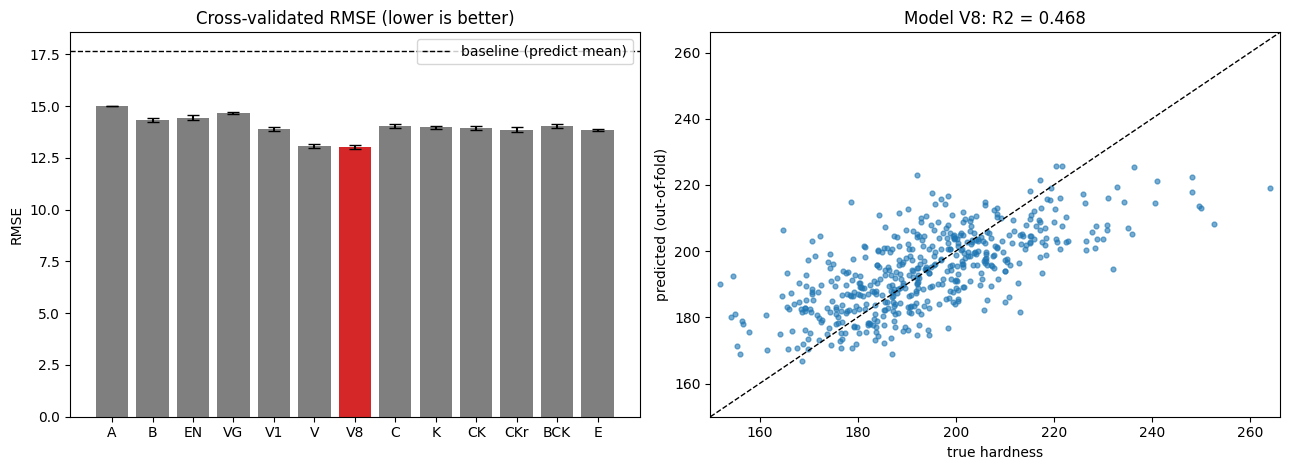

In [ ]:
keys = CANDIDATES
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
axes[0].bar(keys, results.loc[keys, 'CV RMSE'], yerr=results.loc[keys, '± (반복 간)'],
            color=['tab:red' if k == BEST else 'tab:gray' for k in keys], capsize=4)
axes[0].axhline(y.std(), color='k', ls='--', lw=1, label='baseline (predict mean)')
axes[0].set_title('Cross-validated RMSE (lower is better)')
axes[0].set_ylabel('RMSE')
axes[0].legend()

pred_oof = OOF[BEST].mean(axis=0)
lim = [min(y.min(), pred_oof.min()) - 2, max(y.max(), pred_oof.max()) + 2]
axes[1].scatter(y, pred_oof, s=12, alpha=0.6)
axes[1].plot(lim, lim, 'k--', lw=1)
axes[1].set_xlim(lim); axes[1].set_ylim(lim)
axes[1].set_xlabel('true hardness'); axes[1].set_ylabel('predicted (out-of-fold)')
axes[1].set_title(f'Model {BEST}: R2 = {r2_score(y, pred_oof):.3f}')
plt.tight_layout()
plt.show()

## 8-1. 묶음별 모델 vs 통합 모델
제안된 설계 그대로, **묶음(선명·잡음 많음·대비 낮음)마다 Ridge를 따로 학습하고 예측 이미지는 같은 묶음의 모델로 예측**하는 버전을 모든 후보에 만들어, 8단계와 **같은 교차검증 분할**로 통합 모델과 비교합니다. 묶음별 버전은 이름 뒤에 `@G`가 붙고, 9단계 최종 선택에도 후보로 들어갑니다 (더 나으면 그대로 채택).

- 묶음별 모델의 장점: 촬영 상태마다 특징과 경도의 관계가 다르면 그것을 따로 배울 수 있음
- 단점: 모델마다 학습 이미지가 1/3로 줄고, '대비 낮음'처럼 경도와 얽힌 기준으로 나누면 경도 범위도 잘림
- 학습 데이터로 미리 확인한 결과: CK 13.92 → 14.29, ResNet 특징 B 14.50 → 14.80으로 **세 묶음 모두에서 나빠졌습니다.** ViT 특징(V)에서도 그런지 아래 표로 확인하세요.

표의 `차이`가 음수면 묶음별 모델이 더 좋은 것입니다.

In [ ]:
MIN_GROUP_TRAIN = 20     # 학습 이미지가 이보다 적은 묶음은 통합 모델로 예측

def fit_predict_grouped(Xtr_, ytr_, gtr_, Xte_, gte_):
    """묶음마다 따로 학습해 같은 묶음의 이미지를 예측"""
    pred, glob = np.zeros(len(Xte_)), None
    for g in GROUP_CODES:
        v = gte_ == g
        if not v.any():
            continue
        t = gtr_ == g
        if t.sum() >= MIN_GROUP_TRAIN:
            pred[v] = ridge_model().fit(Xtr_[t], ytr_[t]).predict(Xte_[v])
        else:
            if glob is None:
                glob = ridge_model().fit(Xtr_, ytr_)
            pred[v] = glob.predict(Xte_[v])
    return pred

def cv_oof_grouped(X):
    oof = np.zeros((N_REPEATS, len(y)))
    for j, (tr, va) in enumerate(CV_SPLITS):
        oof[j // N_FOLDS, va] = fit_predict_grouped(X[tr], y[tr], GROUP_TR[tr], X[va], GROUP_TR[va])
    return oof

if RUN_GROUP_MODELS:
    rows = {}
    for key, (desc, Xtr, _) in FEATS.items():
        t0 = time.time()
        OOF[key + '@G'] = cv_oof_grouped(Xtr)
        DESC[key + '@G'] = f'{key} 묶음별 모델 (선명·잡음 많음·대비 낮음 따로 학습)'
        a, b = by_group(OOF[key]), by_group(OOF[key + '@G'])
        row = {('전체', '통합'): a['전체'], ('전체', '묶음별'): b['전체'], ('전체', '차이'): b['전체'] - a['전체']}
        for col in GROUP_COLS:
            row.update({(col, '통합'): a[col], (col, '묶음별'): b[col], (col, '차이'): b[col] - a[col]})
        rows[key] = row
        print(f'{key}@G 평가 완료 ({time.time() - t0:.1f}s)')
    group_cmp = pd.DataFrame(rows).T
    group_cmp.columns = pd.MultiIndex.from_tuples(group_cmp.columns)
    display(group_cmp.round(3))
    n_better = int((group_cmp[('전체', '차이')] < 0).sum())
    print(f'묶음별 모델이 통합 모델보다 나은 후보: {n_better}/{len(group_cmp)}개 (전체 RMSE 기준)')
else:
    print('묶음별 모델 비교를 건너뜁니다 (RUN_GROUP_MODELS = False).')

A@G 평가 완료 (0.7s)
B@G 평가 완료 (0.9s)
EN@G 평가 완료 (5.2s)
VG@G 평가 완료 (2.9s)
V1@G 평가 완료 (2.9s)
V@G 평가 완료 (6.9s)
V8@G 평가 완료 (8.8s)
C@G 평가 완료 (0.7s)
K@G 평가 완료 (0.3s)
CK@G 평가 완료 (0.6s)
CKr@G 평가 완료 (0.6s)
BCK@G 평가 완료 (0.9s)


전체                선명 (148)                잡음 많음 (204)                 \
         통합     묶음별     차이       통합     묶음별     차이          통합     묶음별     차이   
A    15.019  15.325  0.306   14.173  14.813  0.640      16.603  16.656  0.052   
B    14.318  14.785  0.467   13.528  14.204  0.676      15.998  16.327  0.329   
EN   14.446  15.017  0.571   13.834  14.698  0.864      16.039  16.523  0.484   
VG   14.661  15.280  0.618   14.012  15.163  1.152      15.962  16.526  0.565   
V1   13.895  14.879  0.984   13.135  13.992  0.856      15.557  16.514  0.958   
V    13.058  13.983  0.925   12.041  12.899  0.858      15.019  15.975  0.957   
V8   13.025  13.936  0.911   12.008  12.879  0.871      14.971  15.934  0.964   
C    14.056  14.382  0.326   13.195  13.635  0.441      15.603  15.848  0.245   
K    13.968  14.365  0.397   12.868  13.086  0.218      15.675  15.976  0.301   
CK   13.921  14.288  0.366   12.947  13.367  0.420      15.524  15.800  0.276   
CKr  13.863  14.322  0.459   13.058  13.691  0.633      15.431  15.743  0.312   
BCK  14.032  14.569  0.536   13.086  13.799  0.713      15.755  16.173  0.418   

    대비 낮음 (148)                 
             통합     묶음별     차이  
A        13.462  13.841  0.380  
B        12.519  13.008  0.488  
EN       12.610  13.020  0.410  
VG       13.365  13.501  0.136  
V1       12.088  13.272  1.184  
V        10.959  11.928  0.968  
V8       10.955  11.837  0.882  
C        12.562  12.908  0.346  
K        12.446  13.192  0.746  
CK       12.446  12.914  0.468  
CKr      12.266  12.794  0.528  
BCK      12.320  12.885  0.565

묶음별 모델이 통합 모델보다 나은 후보: 0/12개 (전체 RMSE 기준)


## 9. 미세조정 (F)
6~8단계는 사전학습 모델을 **고정**한 채 Ridge만 학습했습니다. 여기서는 사전학습 모델 **전체를 경도 예측에 맞게 다시 학습**합니다. 백본은 설정의 `FT_BACKBONE`으로 고르며 기본은 DINOv2 ViT-L/14입니다 (`'resnet18'`이면 이전의 ResNet18 미세조정).

- **DINOv2 출력층**: 고정 특징 V와 같은 방식으로 블록 4개의 CLS·패치 평균·표준편차를 모아 LayerNorm → 선형층 하나로 경도를 냅니다. 선형층을 0으로 시작해서, 처음에는 출력층만 배우고 백본은 그 뒤에 천천히 맞춰집니다 (사전학습 특징이 학습 초반에 망가지지 않게).
- **층별 학습률**: 맨 위 블록은 `FT_LR`(기본 자동: DINOv2 2e-5, CNN 1e-4), 아래 블록으로 갈수록 학습률을 줄입니다 (`FT_LAYER_DECAY`, 맨 아래는 맨 위의 약 3%). 아래층의 일반적인 시각 정보는 거의 그대로 두고 위층을 주로 경도에 맞추는 방식이라, 500장으로 학습해도 덜 망가집니다. 학습 중 블록을 무작위로 건너뛰는 drop path(`FT_DROP_PATH`)로 과적합도 줄입니다.
- **정밀도**: A100·L4처럼 bf16을 지원하는 GPU는 bf16, T4는 fp16으로 자동 선택합니다.
- **시간·메모리**: DINOv2 ViT-L 기준 A100에서 10분 안팎으로 예상하며, T4에서는 몇 배 걸립니다. GPU 메모리가 부족하면 `FT_BATCH = 8`이나 `FT_BACKBONE = 'dinov2_vitb14_reg'`로 바꾸세요. 학습이 실패하면 F 없이 나머지가 그대로 진행됩니다.
- **기본 증강**: 무작위 위치 224×224 자르기 + 90° 회전 + 좌우반전. 예측은 DINOv2면 가운데 252×252(14의 배수), ResNet이면 256 전체를 씁니다.
- **추가 증강 스위치** (설정 셀, 기본은 꺼짐): 임의 각도 회전, 확대·축소, 밝기, 대비. 이 데이터의 미세구조 특징 + Ridge에 같은 증강을 넣어 보면 약한 증강은 차이가 없었고(±0.03), RandomResizedCrop 기본값처럼 크게 확대하는 경우(+0.13)와 강한 밝기·대비 변화(±40%, +0.07)는 오히려 나빠졌습니다. CNN에서는 다를 수 있으니 스위치를 켜고 아래 표로 직접 비교하세요.
- **잡음 증강** (`FT_NOISE_AUG`, 기본 0.5): 2-1단계의 '잡음 많음' 묶음은 예측 이미지의 약 41%인데 오차가 가장 큽니다. 그래서 학습 중 **깨끗한 이미지**를 이 확률로 잡음 묶음처럼 바꿔서 보여줍니다: 대비 0.8~0.9배 → 조명 기울기 최대 15% → 흐림 σ 1.0~1.9px → 노이즈 σ 10~19.5. 같은 미세구조를 두 촬영 조건으로 보게 해서 잡음 이미지에서도 같은 경도를 내도록 만드는 것이 목적입니다. 이 수준은 학습 이미지로 맞췄습니다: 깨끗한 이미지에 입혔을 때 노이즈(16.1 vs 실제 15.6)·흐림(1.59 vs 1.55px)·대비(0.267 vs 0.259)와 조건별 지표 분포가 실제 잡음 묶음과 가깝습니다. 예측할 때는 입히지 않습니다.
- **증강 효과 비교**: 같은 설정의 **증강 없는 F가 캐시에 있으면** `F0`으로 불러와 아래에 나란히 출력하고, 최종 선택에서도 F 대신 F0을 쓴 조합을 함께 비교합니다 (`FT_NOISE_AUG = 0` 으로 한 번 실행했거나 이전 노트북의 F 캐시를 캐시 폴더에 옮겨 둔 경우).
- **시드 평균** (`FT_SEEDS`): 미세조정은 시드(초기값·증강 순서)만 바꿔도 결과가 흔들립니다. 여러 시드로 학습해 평균내면 흔들림이 줄고, 시드별 RMSE도 함께 출력되어 흔들림의 크기를 볼 수 있습니다.
- **평가**: Ridge 후보들과 **같은 5-fold(교차검증 1회차)** 로 학습·검증해 공정하게 비교합니다. epoch 수는 고정이고 검증 fold로 고르지 않으므로 점수가 부풀려지지 않습니다.
- **예측**: 학습된 모델 전부(시드 수 × 5개)의 예측(8방향 TTA)을 평균합니다.
- GPU가 있을 때만 자동 실행됩니다 (`RUN_FINETUNE = 'auto'`). 결과는 설정·시드별로 캐시되어, 같은 설정으로 다시 실행하거나 시드 수만 늘리면 이미 학습한 것은 바로 불러옵니다.

In [ ]:
import copy
import torch.nn as nn
import torch.nn.functional as nnF

USE_AMP = DEVICE == 'cuda'                       # GPU 에서는 16bit 혼합 정밀도로 빠르게
AMP_DEVICE = 'cuda' if USE_AMP else 'cpu'
BF16_OK = USE_AMP and torch.cuda.get_device_capability()[0] >= 8           # A100·L4 등은 bf16, T4(7.x)는 fp16
AMP_DTYPE = torch.float16 if (USE_AMP and not BF16_OK) else torch.bfloat16
FT_IS_VIT = FT_BACKBONE.startswith('dinov2')
FT_LR_EFF = FT_LR if FT_LR is not None else (2e-5 if FT_IS_VIT else 1e-4)   # None 이면 백본에 맞춰 자동
if FT_IS_VIT and FT_CROP % 14:
    FT_CROP = FT_CROP // 14 * 14
    print(f'DINOv2 는 14의 배수만 받아서 FT_CROP 을 {FT_CROP} 으로 바꿉니다.')

def normalize(x01):
    """(B,1,H,W) 값 0~1 → ImageNet 정규화된 (B,3,H,W)"""
    return (x01.repeat(1, 3, 1, 1) - MEAN) / STD

def to_net_input(xb):
    """uint8 (B,H,W) → ImageNet 정규화된 (B,3,H,W) float"""
    return normalize(xb.float().div(255.0).unsqueeze(1))

def fit_patch(x):
    """DINOv2 는 패치(14픽셀)의 배수만 받으므로 가운데를 잘라 맞춤 (ResNet 은 그대로)"""
    if not FT_IS_VIT:
        return x
    H = x.shape[-1]
    S = H // 14 * 14
    c = (H - S) // 2
    return x[:, :, c:c + S, c:c + S]

# '잡음 많음' 묶음의 촬영 상태 (2-1단계 측정값 기준으로 맞춘 범위)
NOISE_AUG_CONTRAST = (0.8, 0.9)     # 대비 배율
NOISE_AUG_GRADIENT = 0.15           # 조명 기울기: 이미지 끝에서 끝까지 밝기 변화 최대 15%
NOISE_AUG_BLUR     = (1.0, 1.9)     # 흐림 σ (픽셀, 원래 흐림 약 0.8 포함)
NOISE_AUG_SIGMA    = (10.0, 19.5)   # 노이즈 σ (0~255 눈금)

def degrade_like_noisy(x, rng):
    """x: (n,1,h,w) 값 0~1 → 잡음 많음 묶음처럼 대비↓ + 조명 기울기 + 흐림 + 노이즈"""
    n, _, h, w = x.shape
    gy, gx = torch.meshgrid(torch.linspace(-0.5, 0.5, h, device=x.device),
                            torch.linspace(-0.5, 0.5, w, device=x.device), indexing='ij')
    out = []
    for i in range(n):
        xi = x[i:i + 1]
        m = xi.mean()
        xi = m + float(rng.uniform(*NOISE_AUG_CONTRAST)) * (xi - m)
        th, g = float(rng.uniform(0, 2 * np.pi)), float(rng.uniform(0, NOISE_AUG_GRADIENT))
        xi = xi * (1 + g * (float(np.cos(th)) * gx + float(np.sin(th)) * gy))
        s = float(np.sqrt(max(rng.uniform(*NOISE_AUG_BLUR) ** 2 - 0.8 ** 2, 0.05)))   # 추가로 필요한 흐림
        r = int(np.ceil(3 * s))
        t = torch.arange(-r, r + 1, device=x.device, dtype=x.dtype)
        k = torch.exp(-(t * t) / (2 * s * s))
        k = k / k.sum()
        xi = nnF.conv2d(nnF.pad(xi, (r, r, 0, 0), mode='reflect'), k.view(1, 1, 1, -1))   # 가로 흐림
        xi = nnF.conv2d(nnF.pad(xi, (0, 0, r, r), mode='reflect'), k.view(1, 1, -1, 1))   # 세로 흐림
        xi = xi + float(rng.uniform(*NOISE_AUG_SIGMA)) / 255.0 * torch.randn_like(xi)
        out.append(xi)
    return torch.cat(out)

def augment(xb, rng, clean=None):
    """학습용 증강: uint8 (B,H,W) → (B,1,FT_CROP,FT_CROP), 값 0~1. clean: 깨끗한 이미지 여부 (잡음 증강 대상)"""
    B, H, W = xb.shape
    x = xb.float().div(255.0).unsqueeze(1)
    if FT_ROTATE_ANY or FT_SCALE_JITTER > 0:
        # 회전·확대·이동을 한 번에 (가장자리는 거울 반사로 채워 검은 모서리가 생기지 않음)
        ang = rng.uniform(0, 2 * np.pi, B) if FT_ROTATE_ANY else rng.integers(0, 4, B) * (np.pi / 2)
        sc = (FT_CROP / H) * rng.uniform(1 - FT_SCALE_JITTER, 1 + FT_SCALE_JITTER, B)
        room = np.clip(1 - sc, 0, None)
        tx, ty = rng.uniform(-1, 1, B) * room, rng.uniform(-1, 1, B) * room
        theta = np.stack([np.stack([sc * np.cos(ang), -sc * np.sin(ang), tx], 1),
                          np.stack([sc * np.sin(ang), sc * np.cos(ang), ty], 1)], 1)    # (B,2,3)
        grid = nnF.affine_grid(torch.as_tensor(theta, dtype=torch.float32, device=DEVICE),
                               (B, 1, FT_CROP, FT_CROP), align_corners=False)
        x = nnF.grid_sample(x, grid, mode='bilinear', padding_mode='reflection', align_corners=False)
    else:
        # 기본: 무작위 위치 자르기 + 90° 회전 (보간 없음)
        out = []
        for i in range(B):
            t = int(rng.integers(0, H - FT_CROP + 1))
            l = int(rng.integers(0, W - FT_CROP + 1))
            out.append(torch.rot90(x[i, :, t:t + FT_CROP, l:l + FT_CROP], int(rng.integers(4)), dims=(1, 2)))
        x = torch.stack(out)
    flip = torch.as_tensor(rng.random(B) < 0.5, device=DEVICE).view(B, 1, 1, 1)
    x = torch.where(flip, torch.flip(x, dims=(3,)), x)                    # 좌우반전
    if FT_NOISE_AUG > 0 and clean is not None:                             # 깨끗한 이미지 일부를 잡음 묶음처럼
        sel = np.nonzero(np.asarray(clean) & (rng.random(B) < FT_NOISE_AUG))[0]
        if len(sel):
            idx = torch.as_tensor(sel, device=DEVICE)
            x[idx] = degrade_like_noisy(x[idx], rng)
    if FT_BRIGHTNESS > 0:
        f = rng.uniform(1 - FT_BRIGHTNESS, 1 + FT_BRIGHTNESS, B)
        x = x * torch.as_tensor(f, dtype=torch.float32, device=DEVICE).view(B, 1, 1, 1)
    if FT_CONTRAST > 0:
        f = rng.uniform(1 - FT_CONTRAST, 1 + FT_CONTRAST, B)
        m = x.mean(dim=(2, 3), keepdim=True)
        x = m + torch.as_tensor(f, dtype=torch.float32, device=DEVICE).view(B, 1, 1, 1) * (x - m)
    return x.clamp(0, 1)

class DinoRegressor(nn.Module):
    """DINOv2 백본 + 블록 4개의 CLS·패치 평균·표준편차 → LayerNorm → 선형층 (경도 1개)"""
    def __init__(self, backbone):
        super().__init__()
        self.backbone = backbone
        n = len(backbone.blocks)
        self.take = [n * (i + 1) // 4 - 1 for i in range(4)]
        dim = 3 * backbone.embed_dim * len(self.take)
        self.head = nn.Sequential(nn.LayerNorm(dim), nn.Dropout(0.2), nn.Linear(dim, 1))
        with torch.no_grad():                      # 0 에서 시작: 처음엔 출력층만 배우고 백본은 그 뒤에 천천히 맞춰짐
            self.head[-1].weight.zero_()
            self.head[-1].bias.zero_()

    def forward(self, x):
        outs = self.backbone.get_intermediate_layers(x, n=self.take, return_class_token=True, norm=True)
        feats = torch.cat([torch.cat([c, p.mean(dim=1), p.std(dim=1)], dim=1) for p, c in outs], dim=1)
        return self.head(feats.float())

_FT_BASE = None

def ft_base():
    """사전학습 DINOv2 를 한 번만 불러 두고 fold 마다 복사해서 씀"""
    global _FT_BASE
    if _FT_BASE is None:
        kw = dict(trust_repo=True, skip_validation=True)
        try:
            _FT_BASE = torch.hub.load('facebookresearch/dinov2', FT_BACKBONE, drop_path_rate=FT_DROP_PATH, **kw)
        except TypeError:                                                  # drop_path_rate 를 받지 않는 버전
            _FT_BASE = torch.hub.load('facebookresearch/dinov2', FT_BACKBONE, **kw)
    return _FT_BASE

def make_model():
    """→ (모델, 옵티마이저 파라미터 그룹: 그룹마다 최대 학습률 'lr' 과 weight_decay)"""
    if not FT_IS_VIT:
        if FT_BACKBONE == 'efficientnet_b0':
            m = efficientnet_b0(weights=EfficientNet_B0_Weights.IMAGENET1K_V1)
            m.classifier = nn.Sequential(nn.Dropout(0.2), nn.Linear(m.classifier[-1].in_features, 1))
            new = m.classifier
        elif FT_BACKBONE == 'vgg16':
            m = vgg16(weights=VGG16_Weights.IMAGENET1K_V1)
            m.classifier[-1] = nn.Linear(m.classifier[-1].in_features, 1)              # 마지막 층만 경도 1개로 교체
            new = m.classifier[-1]
        elif FT_BACKBONE == 'resnet18':
            m = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)
            m.fc = nn.Sequential(nn.Dropout(0.2), nn.Linear(m.fc.in_features, 1))   # 출력: 경도 1개
            new = m.fc
        else:
            raise ValueError(f'지원하지 않는 FT_BACKBONE: {FT_BACKBONE}')
        m = m.to(DEVICE)
        head = list(new.parameters())
        body = [p for p in m.parameters() if all(p is not h for h in head)]
        return m, [{'params': body, 'lr': FT_LR_EFF, 'weight_decay': 1e-4},
                   {'params': head, 'lr': FT_HEAD_LR, 'weight_decay': 1e-4}]
    m = DinoRegressor(copy.deepcopy(ft_base())).to(DEVICE)
    n = len(m.backbone.blocks)
    decay = FT_LAYER_DECAY ** (12 / n)            # 깊이와 상관없이 맨 아래층 학습률이 맨 위의 약 3% 가 되도록
    groups = {}
    for name, p in m.backbone.named_parameters():
        if name.startswith('blocks.'):
            layer = int(name.split('.')[1]) + 1
        elif name.startswith('norm.'):
            layer = n                             # 마지막 LayerNorm 은 맨 위 블록과 같게
        else:
            layer = 0                             # 패치 임베딩·위치 임베딩·CLS·레지스터 토큰
        wd = 0.0 if p.ndim == 1 or name.endswith(('token', 'tokens', 'pos_embed')) else 0.05
        g = groups.setdefault((layer, wd), {'params': [], 'lr': FT_LR_EFF * decay ** (n - layer), 'weight_decay': wd})
        g['params'].append(p)
    return m, list(groups.values()) + [{'params': list(m.head.parameters()), 'lr': FT_HEAD_LR, 'weight_decay': 0.05}]

def make_scaler(enabled):
    try:
        return torch.amp.GradScaler('cuda', enabled=enabled)
    except (AttributeError, TypeError):                                    # 오래된 torch
        return torch.cuda.amp.GradScaler(enabled=enabled)

@torch.no_grad()
def predict_cnn(model, imgs, y_mu, y_sd, tta=True, batch_size=64):
    model.eval()
    views = [(k, flip) for k in range(4) for flip in (False, True)] if tta else [(0, False)]
    out = []
    for s in range(0, imgs.shape[0], batch_size):
        x = fit_patch(to_net_input(imgs[s:s + batch_size]))
        acc = 0
        for k, flip in views:
            v = torch.rot90(x, k, dims=(2, 3))
            if flip:
                v = torch.flip(v, dims=(3,))
            with torch.autocast(device_type=AMP_DEVICE, dtype=AMP_DTYPE, enabled=USE_AMP):
                acc = acc + model(v).squeeze(1).float()
        out.append((acc / len(views)).cpu().numpy())
    return np.concatenate(out) * y_sd + y_mu

def train_fold(tr, va, fold, seed, label):
    torch.manual_seed(seed + fold)
    rng = np.random.default_rng(seed + fold)
    y_mu, y_sd = y[tr].mean(), y[tr].std()                               # 학습 fold 기준으로 표준화
    y_t = torch.as_tensor((y - y_mu) / y_sd, dtype=torch.float32, device=DEVICE)
    model, groups = make_model()
    opt = torch.optim.AdamW(groups)
    steps = FT_EPOCHS * int(np.ceil(len(tr) / FT_BATCH))
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=[g['lr'] for g in groups], total_steps=steps, pct_start=0.15)
    scaler = make_scaler(USE_AMP and AMP_DTYPE == torch.float16)          # bf16 은 스케일링이 필요 없음
    va_t = torch.as_tensor(va, device=DEVICE)
    for ep in range(1, FT_EPOCHS + 1):
        model.train()
        order = rng.permutation(tr)
        for s in range(0, len(order), FT_BATCH):
            b = order[s:s + FT_BATCH]
            if len(b) < 2:                                                # BatchNorm 은 2장 이상 필요
                continue
            bt = torch.as_tensor(b, device=DEVICE)
            x = fit_patch(normalize(augment(X_TR_GPU[bt], rng, ~NOISY_TR[b])))
            with torch.autocast(device_type=AMP_DEVICE, dtype=AMP_DTYPE, enabled=USE_AMP):
                out = model(x).squeeze(1)
            loss = nnF.mse_loss(out.float(), y_t[bt])
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()
            sched.step()
        if ep % 5 == 0 or ep == FT_EPOCHS:                                # 진행 상황 확인용 (선택에는 안 씀)
            p = predict_cnn(model, X_TR_GPU[va_t], y_mu, y_sd, tta=False)
            print(f'  [{label}] fold {fold + 1} epoch {ep:2d}: 검증 RMSE {np.sqrt(np.mean((p - y[va]) ** 2)):.3f}')
    va_pred = predict_cnn(model, X_TR_GPU[va_t], y_mu, y_sd, tta=USE_TTA)
    te_pred = predict_cnn(model, X_TE_GPU, y_mu, y_sd, tta=USE_TTA)
    del model, opt
    if DEVICE == 'cuda':
        torch.cuda.empty_cache()
    return va_pred, te_pred

def ft_tag(noise_aug):
    """미세조정 캐시 이름: 설정이나 교차검증 분할이 바뀌면 새로 학습 (잡음 증강을 끄면 이전 노트북의 캐시와 같은 이름)"""
    return (f'{data_key(X_tr_img)}_{data_key(X_te_img)}_{FT_BACKBONE}_e{FT_EPOCHS}_lr{FT_LR_EFF:g}_hl{FT_HEAD_LR:g}'
            f'_b{FT_BATCH}_c{FT_CROP}_f{N_FOLDS}_tta{int(USE_TTA)}_ra{int(FT_ROTATE_ANY)}_sj{FT_SCALE_JITTER:g}'
            f'_br{FT_BRIGHTNESS:g}_ct{FT_CONTRAST:g}' + (f'_ld{FT_LAYER_DECAY:g}_dp{FT_DROP_PATH:g}' if FT_IS_VIT else '')
            + (f'_na{noise_aug:g}' if noise_aug > 0 else '') + f'_sp{SPLIT_TAG}_v3')

def report_f(name, oof):
    g = by_group(oof)
    print(f'{name}: 교차검증 RMSE {g["전체"]:.3f} | ' + ', '.join(f'{c} {g[c]:.2f}' for c in GROUP_COLS))

OOF_F, TEST_F, OOF_F0, TEST_F0 = None, None, None, None
run_ft = (DEVICE == 'cuda') if RUN_FINETUNE == 'auto' else bool(RUN_FINETUNE)
if run_ft:
    print(f'미세조정 백본: {FT_BACKBONE} (학습률 {FT_LR_EFF:g}) | 정밀도: {"bf16" if AMP_DTYPE == torch.bfloat16 and USE_AMP else ("fp16" if USE_AMP else "fp32")}'
          f' | 잡음 증강: {"깨끗한 이미지의 " + format(FT_NOISE_AUG, ".0%") if FT_NOISE_AUG > 0 else "끔"}')
    try:
        if DEVICE == 'cuda':
            torch.backends.cudnn.benchmark = True
        X_TR_GPU = torch.from_numpy(X_tr_img).to(DEVICE)
        X_TE_GPU = torch.from_numpy(X_te_img).to(DEVICE)
        tag = ft_tag(FT_NOISE_AUG)
        oofs, tests = [], []
        for si in range(FT_SEEDS):
            seed, label = SEED + 1000 * si, f'시드 {si + 1}'
            f = CACHE_DIR / f'finetune_{tag}_seed{seed}.npz'
            if f.exists():
                d = np.load(f)
                oof, test = d['oof'], d['test']
                print(f'[{label}] 캐시 사용 ({f.name})')
            else:
                t0 = time.time()
                oof, fold_tests = np.zeros(len(y)), []
                for fold, (tr, va) in enumerate(CV_SPLITS[:N_FOLDS]):     # Ridge 후보와 같은 5-fold (1회차)
                    va_pred, te_pred = train_fold(tr, va, fold, seed, label)
                    oof[va] = va_pred
                    fold_tests.append(te_pred)
                    print(f'[{label}] fold {fold + 1}/{N_FOLDS} 완료 ({time.time() - t0:.0f}s 경과)')
                test = np.mean(fold_tests, axis=0)                         # fold 모델 5개 평균
                if not (np.isfinite(oof).all() and np.isfinite(test).all()):
                    raise RuntimeError('예측에 NaN/inf 가 생겼습니다 (16bit 학습이 불안정했을 수 있음)')
                np.savez(f, oof=oof, test=test)
            print(f'[{label}] F 교차검증 RMSE = {np.sqrt(np.mean((oof - y) ** 2)):.3f}')
            oofs.append(oof)
            tests.append(test)
        OOF_F, TEST_F = np.mean(oofs, axis=0), np.mean(tests, axis=0)      # 시드 평균
        if FT_SEEDS > 1:
            print(f'→ 시드 {FT_SEEDS}개 평균 F 교차검증 RMSE = {np.sqrt(np.mean((OOF_F - y) ** 2)):.3f}')
        report_f(f'F ({"잡음 증강" if FT_NOISE_AUG > 0 else "증강 없음"}, 시드 {FT_SEEDS}개)', OOF_F)
        if FT_NOISE_AUG > 0:                                               # 같은 설정의 증강 없는 F 캐시 → F0 으로 비교
            found = [CACHE_DIR / f'finetune_{ft_tag(0)}_seed{SEED + 1000 * si}.npz' for si in range(FT_SEEDS)]
            found = [f for f in found if f.exists()]
            if found:
                d0 = [np.load(f) for f in found]
                OOF_F0, TEST_F0 = np.mean([d['oof'] for d in d0], axis=0), np.mean([d['test'] for d in d0], axis=0)
                report_f(f'F0 (증강 없음, 캐시 시드 {len(found)}개)', OOF_F0)
            else:
                print('증강 없는 F 캐시가 없어 F0 비교는 건너뜁니다 (FT_NOISE_AUG = 0 으로 한 번 실행하면 생김).')
    except Exception as e:
        hint = (' → FT_BATCH 를 줄이거나 FT_BACKBONE 을 dinov2_vitb14_reg 로 바꿔 보세요.'
                if 'out of memory' in str(e).lower() else '')
        print(f'※ 미세조정(F)에 실패해 F 없이 진행합니다 ({type(e).__name__}: {str(e)[:300]}){hint}')
        OOF_F, TEST_F, OOF_F0, TEST_F0 = None, None, None, None
    _FT_BASE = None                                                        # 백본 원본을 메모리에서 비움
    gc.collect()
    if DEVICE == 'cuda':
        torch.cuda.empty_cache()
else:
    print('미세조정(F)을 건너뜁니다. GPU 런타임에서 실행하거나 설정 셀의 RUN_FINETUNE 을 바꾸세요.')

미세조정 백본: dinov2_vitl14_reg (학습률 2e-05) | 정밀도: bf16 | 잡음 증강: 깨끗한 이미지의 50%


Using cache found in /root/.cache/torch/hub/facebookresearch_dinov2_main


Downloading: "https://dl.fbaipublicfiles.com/dinov2/dinov2_vitl14/dinov2_vitl14_reg4_pretrain.pth" to /root/.cache/torch/hub/checkpoints/dinov2_vitl14_reg4_pretrain.pth


100%|██████████| 1.13G/1.13G [00:23<00:00, 52.9MB/s]


  [시드 1] fold 1 epoch  5: 검증 RMSE 19.080
  [시드 1] fold 1 epoch 10: 검증 RMSE 12.996
  [시드 1] fold 1 epoch 15: 검증 RMSE 13.099
  [시드 1] fold 1 epoch 20: 검증 RMSE 13.084
[시드 1] fold 1/5 완료 (101s 경과)
  [시드 1] fold 2 epoch  5: 검증 RMSE 29.640
  [시드 1] fold 2 epoch 10: 검증 RMSE 20.215
  [시드 1] fold 2 epoch 15: 검증 RMSE 13.294
  [시드 1] fold 2 epoch 20: 검증 RMSE 13.254
[시드 1] fold 2/5 완료 (172s 경과)
  [시드 1] fold 3 epoch  5: 검증 RMSE 16.587
  [시드 1] fold 3 epoch 10: 검증 RMSE 13.283
  [시드 1] fold 3 epoch 15: 검증 RMSE 13.923
  [시드 1] fold 3 epoch 20: 검증 RMSE 13.815
[시드 1] fold 3/5 완료 (242s 경과)
  [시드 1] fold 4 epoch  5: 검증 RMSE 19.168
  [시드 1] fold 4 epoch 10: 검증 RMSE 14.663
  [시드 1] fold 4 epoch 15: 검증 RMSE 14.190
  [시드 1] fold 4 epoch 20: 검증 RMSE 14.308
[시드 1] fold 4/5 완료 (313s 경과)
  [시드 1] fold 5 epoch  5: 검증 RMSE 17.754
  [시드 1] fold 5 epoch 10: 검증 RMSE 12.880
  [시드 1] fold 5 epoch 15: 검증 RMSE 13.009
  [시드 1] fold 5 epoch 20: 검증 RMSE 12.369
[시드 1] fold 5/5 완료 (383s 경과)
[시드 1] F 교차검증 RMSE = 13.165
  [시드 2

### 최종 모델 선택 — 1등 하나 대신 평균도 후보로
후보끼리 교차검증 차이가 0.1 안팎으로 작을 때는 1등 하나를 고르는 것이 운에 크게 흔들립니다. 실제로 교차검증에서 근소하게 앞선 단일 모델이 Public 점수에서는 더 나빴습니다. 성격이 다른 모델은 틀리는 이미지도 달라서, 같은 비중으로 평균하면 오차가 서로 일부 상쇄됩니다. 그래서 아래 후보를 **같은 5-fold 기준 RMSE**로 비교합니다.

| 후보 | 구성 |
|---|---|
| Ridge 최고 | 8단계 1등 |
| F | 미세조정 (기본 DINOv2 ViT-L) |
| F + Ridge 최고 | 둘의 평균 |
| CNN 특징 + 측정 특징 | CNN 고정 특징 Ridge(A·B·EN·VG 중 가장 나은 것)와 측정 특징 Ridge(C·K·CK·CKr 중 나은 것)의 평균 |
| CNN 특징 + 측정 특징 + F | 셋의 평균 |
| ViT 특징 + 측정 특징 (+ F) | 위 두 후보에서 CNN 특징 대신 ViT 고정 특징 Ridge(V1·V·V8 중 나은 것) |
| CNN 특징 + ViT 특징 + 측정 특징 (+ F) | CNN·ViT 특징을 둘 다 넣은 평균 |
| ViT 특징 + 두 번째 모델 S (+ 측정 특징) (+ F) | DINOv2와 학습 방식이 다른 모델(6-3단계)을 함께 넣은 평균 |
| 묶음별 모델 (`@G`) | Ridge 최고, ViT + 측정 특징, CNN + 측정 특징을 **묶음마다 따로 학습**한 버전 (8-1단계, 제안된 설계) |
| F0 조합 | F가 든 조합마다 F 대신 **잡음 증강 없는 F0**(캐시)을 넣은 버전 — 증강 효과를 같은 표에서 비교 |
| GW (묶음별 평균 비중) | ViT·측정 특징·F(F·F0 중 나은 것)를 **묶음마다 다른 비중**으로 평균. 지금까지 잡음·선명 묶음은 F, 대비 낮음 묶음은 고정 특징 V가 가장 정확했던 점을 살리는 방식 |

ViT·S·F·F0·`@G`·GW 후보는 해당 단계를 실행한 경우에만 나타납니다. 1등과의 RMSE 차이가 설정의 `ENSEMBLE_TOL`(기본 0.05) 이내인 후보 중에서는 **더 많은 모델을 평균한 후보**를 고릅니다. `ENSEMBLE_TOL = 0` 이면 무조건 1등을 고릅니다. 표 오른쪽 열은 같은 예측의 묶음별 RMSE입니다.

**GW 평가 방법**: 비중은 0.1 단위로 합이 1이 되는 조합 중에서 고릅니다. 고르는 과정까지 교차검증 안에 넣어서(검증 fold의 이미지는 비중 선택에 쓰지 않음) 점수가 부풀려지지 않게 했습니다. 비중을 골라 맞춘 만큼 단순 평균보다 불안정할 수 있으므로, **단순 평균 1등보다 RMSE가 낮을 때만** 최종 모델로 고릅니다.

,모델 수,구성,CV RMSE (같은 5-fold),CV R²,선명 (148),잡음 많음 (204),대비 낮음 (148)
후보,,,,,,,
V8,1,Ridge V8,13.098,0.451,12.158,15.031,10.970
F,1,"미세조정 F (dinov2_vitl14_reg, 잡음 증강)",12.888,0.469,11.905,14.342,11.658
F+V8,2,"미세조정 F (dinov2_vitl14_reg, 잡음 증강) + Ridge V8",12.778,0.478,11.812,14.460,11.131
B+CKr,2,Ridge B + Ridge CKr,13.866,0.385,13.078,15.461,12.208
B+CKr+F,3,Ridge B + Ridge CKr + 미세조정 F (dinov2_vitl14_re...,13.317,0.433,12.471,14.833,11.846
V8+CKr,2,Ridge V8 + Ridge CKr,13.117,0.450,12.367,14.815,11.216
V8+CKr+F,3,Ridge V8 + Ridge CKr + 미세조정 F (dinov2_vitl14_r...,12.893,0.468,12.077,14.497,11.230
B+V8+CKr,3,Ridge B + Ridge V8 + Ridge CKr,13.355,0.429,12.532,15.043,11.559
B+V8+CKr+F,4,Ridge B + Ridge V8 + Ridge CKr + 미세조정 F (dinov...,13.105,0.451,12.241,14.717,11.480


GW 묶음별 비중 (학습 이미지 전체로 고른 값, 최종 예측에 사용):


,V8,CKr,F
선명,0.4,0.0,0.6
잡음 많음,0.1,0.1,0.8
대비 낮음,0.9,0.1,0.0


1등: F+V8 (12.778) → 최종 모델: F+V8 (12.778, 모델 2개 평균)
GW(12.867)는 단순 평균 1등(12.778)보다 낫지 않아 쓰지 않습니다.


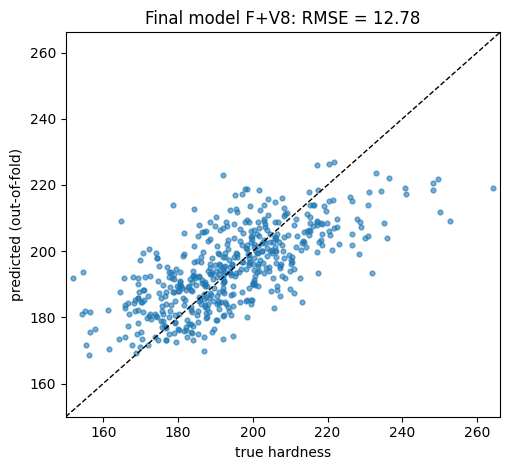

In [ ]:
# 모델 '가족'별 대표: ResNet 고정 특징 / ViT 고정 특징 / 측정 특징 Ridge
CNN_KEY = min([k for k in ('A', 'B', 'EN', 'VG') if k in FEATS], key=lambda k: results.loc[k, 'CV RMSE'])
VIT_KEY = min([k for k in ('V1', 'V', 'V8') if k in FEATS], key=lambda k: results.loc[k, 'CV RMSE'], default=None)
FEAT_KEY = min([k for k in ('C', 'K', 'CK', 'CKr') if k in FEATS], key=lambda k: results.loc[k, 'CV RMSE'])
EXTRA_KEY = 'S' if 'S' in FEATS else None

def GK(k):
    """묶음별 버전의 이름 (8-1단계를 실행하지 않았으면 None)"""
    return k + '@G' if (k is not None and k + '@G' in OOF) else None

# 같은 5-fold(교차검증 1회차)의 out-of-fold 예측끼리 비교 (F 와 같은 fold)
member_oof = {k: OOF[k][0] for k in (BEST, CNN_KEY, VIT_KEY, EXTRA_KEY, FEAT_KEY, GK(BEST), GK(CNN_KEY), GK(VIT_KEY), GK(FEAT_KEY))
              if k is not None}
if OOF_F is not None:
    member_oof['F'] = OOF_F
if OOF_F0 is not None:
    member_oof['F0'] = OOF_F0

COMBOS = [(BEST,), ('F',), ('F', BEST),
          (CNN_KEY, FEAT_KEY), (CNN_KEY, FEAT_KEY, 'F'),                      # CNN + 측정 (+ F)
          (VIT_KEY, FEAT_KEY), (VIT_KEY, FEAT_KEY, 'F'),                      # CNN 대신 ViT
          (CNN_KEY, VIT_KEY, FEAT_KEY), (CNN_KEY, VIT_KEY, FEAT_KEY, 'F'),    # CNN·ViT 둘 다
          (VIT_KEY, EXTRA_KEY), (VIT_KEY, EXTRA_KEY, FEAT_KEY),               # ViT + 두 번째 모델
          (VIT_KEY, EXTRA_KEY, FEAT_KEY, 'F')]
COMBOS += [tuple('F0' if m == 'F' else m for m in c) for c in COMBOS if 'F' in c]   # 잡음 증강 없는 F0 으로 바꾼 조합
COMBOS += [(GK(BEST),), (GK(VIT_KEY), GK(FEAT_KEY)), (GK(CNN_KEY), GK(FEAT_KEY))]  # 묶음별 모델 (제안된 설계)

def member_desc(m):
    if m == 'F':
        return f'미세조정 F ({FT_BACKBONE}{", 잡음 증강" if FT_NOISE_AUG > 0 else ""})'
    if m == 'F0':
        return f'미세조정 F0 ({FT_BACKBONE}, 증강 없음)'
    return f'묶음별 Ridge {m[:-2]}' if m.endswith('@G') else f'Ridge {m}'

def simplex_grid(n, step=0.1):
    """합이 1인 n개 비중을 step 단위로 모두 나열"""
    k = int(round(1 / step))
    out = []
    def rec(prefix, left, slots):
        if slots == 1:
            out.append(prefix + [left])
            return
        for i in range(left + 1):
            rec(prefix + [i], left - i, slots - 1)
    rec([], k, n)
    return np.array(out, dtype=np.float64) / k

rows, seen = [], set()
for combo in COMBOS:
    if any(m not in member_oof for m in combo) or frozenset(combo) in seen:
        continue                                   # V·S·F·@G 가 없으면 그것이 든 후보는 건너뜀, 중복 조합도 건너뜀
    seen.add(frozenset(combo))
    p = np.mean([member_oof[m] for m in combo], axis=0)
    g = by_group(p)
    rows.append({'후보': '+'.join(combo), '모델 수': len(combo), '구성': ' + '.join(member_desc(m) for m in combo),
                 'CV RMSE (같은 5-fold)': rmse(p, y), 'CV R²': r2_score(y, p), **{c: g[c] for c in GROUP_COLS}})
cmp = pd.DataFrame(rows).set_index('후보')

# ---------- GW: 묶음마다 다른 평균 비중 (비중 고르기까지 교차검증 안에서) ----------
F_BEST = min([m for m in ('F', 'F0') if m in member_oof], key=lambda m: rmse(member_oof[m], y), default=None)
GW_MEMBERS = list(dict.fromkeys(m for m in (VIT_KEY or CNN_KEY, FEAT_KEY, F_BEST, EXTRA_KEY) if m is not None and m in member_oof))
GW_W = None
if len(GW_MEMBERS) >= 2:
    P_gw = np.stack([member_oof[m] for m in GW_MEMBERS])           # (모델 수, 샘플 수)
    GRID = simplex_grid(len(GW_MEMBERS), 0.1)
    equal_w = np.full(len(GW_MEMBERS), 1 / len(GW_MEMBERS))

    def fit_w(idx):
        if len(idx) < MIN_GROUP_TRAIN:
            return equal_w
        return GRID[int(np.argmin(((GRID @ P_gw[:, idx] - y[idx]) ** 2).mean(axis=1)))]

    gw_oof = np.zeros(len(y))
    for tr, va in CV_SPLITS[:N_FOLDS]:                              # 검증 fold 의 이미지는 비중 고르는 데 쓰지 않음
        for g in GROUP_CODES:
            v = va[GROUP_TR[va] == g]
            if len(v):
                gw_oof[v] = fit_w(tr[GROUP_TR[tr] == g]) @ P_gw[:, v]
    GW_W = {g: fit_w(np.nonzero(GROUP_TR == g)[0]) for g in GROUP_CODES}   # 최종 예측용: 학습 이미지 전체로 고른 비중
    member_oof['GW'] = gw_oof
    DESC['GW'] = '묶음별 평균 비중: ' + ' · '.join(GW_MEMBERS)
    gg = by_group(gw_oof)
    cmp = pd.concat([cmp, pd.DataFrame([{'모델 수': len(GW_MEMBERS), '구성': DESC['GW'], 'CV RMSE (같은 5-fold)': rmse(gw_oof, y),
                                         'CV R²': r2_score(y, gw_oof), **{c: gg[c] for c in GROUP_COLS}}],
                                       index=pd.Index(['GW'], name='후보'))])
display(cmp.round(3))
if GW_W is not None:
    print('GW 묶음별 비중 (학습 이미지 전체로 고른 값, 최종 예측에 사용):')
    display(pd.DataFrame({GROUP_KO[g]: GW_W[g] for g in GROUP_CODES}, index=GW_MEMBERS).T.round(1))

simple = cmp.drop(index='GW', errors='ignore')                      # 같은 비중으로 평균한 후보들
best_rmse = simple['CV RMSE (같은 5-fold)'].min()
near = simple[simple['CV RMSE (같은 5-fold)'] <= best_rmse + ENSEMBLE_TOL]
FINAL = near.sort_values(['모델 수', 'CV RMSE (같은 5-fold)'], ascending=[False, True]).index[0]
print(f'1등: {simple["CV RMSE (같은 5-fold)"].idxmin()} ({best_rmse:.3f}) → 최종 모델: {FINAL} '
      f'({cmp.loc[FINAL, "CV RMSE (같은 5-fold)"]:.3f}, 모델 {cmp.loc[FINAL, "모델 수"]}개 평균)')
if 'GW' in cmp.index:
    gw_rmse = cmp.loc['GW', 'CV RMSE (같은 5-fold)']
    if gw_rmse < best_rmse:
        FINAL = 'GW'
        print(f'→ GW({gw_rmse:.3f})가 단순 평균 1등({best_rmse:.3f})보다 좋아서 GW 를 최종 모델로 바꿉니다.')
    else:
        print(f'GW({gw_rmse:.3f})는 단순 평균 1등({best_rmse:.3f})보다 낫지 않아 쓰지 않습니다.')

p = member_oof['GW'] if FINAL == 'GW' else np.mean([member_oof[m] for m in FINAL.split('+')], axis=0)
lim = [min(y.min(), p.min()) - 2, max(y.max(), p.max()) + 2]
plt.figure(figsize=(5.2, 4.8))
plt.scatter(y, p, s=12, alpha=0.6)
plt.plot(lim, lim, 'k--', lw=1)
plt.xlim(lim)
plt.ylim(lim)
plt.xlabel('true hardness')
plt.ylabel('predicted (out-of-fold)')
plt.title(f'Final model {FINAL}: RMSE = {rmse(p, y):.2f}')
plt.tight_layout()
plt.show()

## 10. 최종 학습 및 1000장 예측
최종 모델에 들어간 Ridge 후보는 **학습 이미지 500장 전체**로 다시 학습한 뒤(alpha도 500장 기준으로 다시 고름) 예측 이미지에 적용하고, F는 9단계에서 학습한 모델들(시드 수 × 5개)의 예측 평균을 그대로 씁니다. 최종 모델이 여러 모델의 평균이면 각 모델의 예측을 같은 비중으로 평균합니다.

다른 조합을 직접 쓰고 싶으면 아래 셀 첫 줄의 주석을 풀고 `FINAL`을 바꾸세요 (예: `'B+CK+F'`, `'V+CKr'`, 묶음별 모델 `'V@G+CK@G'`). 8단계 후보 이름(8-1단계의 `@G` 포함)과 `F`를 `+`로 이으면 어떤 조합이든 됩니다. 마지막 줄의 묶음별 예측 평균이 같은 묶음의 학습 경도 평균과 크게 다르면 그 묶음의 예측을 의심해 보세요.

In [ ]:
# FINAL = 'B+V+CK+F'        # ← 조합을 직접 고르고 싶을 때만 주석을 풀어 사용 ('GW' 도 가능)
if FINAL == 'GW' and GW_W is None:
    raise ValueError("FINAL = 'GW' 는 9단계에서 GW 가 만들어졌을 때만 쓸 수 있습니다.")
FINAL_MEMBERS = GW_MEMBERS if FINAL == 'GW' else FINAL.split('+')

def available(m):
    if m == 'F':
        return TEST_F is not None
    if m == 'F0':
        return TEST_F0 is not None
    return m in DESC

unknown = [m for m in FINAL_MEMBERS if not available(m)]
if unknown:
    raise ValueError(f'FINAL 의 {unknown} 은(는) 이번 실행에 없는 후보입니다. 8·9단계 표에 나온 이름만 쓸 수 있습니다.')

def ridge_test_pred(key):
    """Ridge 후보를 학습 이미지 전체로 다시 학습해 예측 이미지에 적용"""
    if key == 'E':                                             # E = B 와 CK 예측의 평균
        return (ridge_test_pred('B') + ridge_test_pred('CK')) / 2
    if key.endswith('@G'):                                     # 묶음별 모델: 묶음마다 그 묶음의 학습 이미지 전체로 따로 학습
        _, Xtr, Xte = FEATS[key[:-2]]
        print(f'  Ridge {key}: 묶음별로 따로 학습 (' + ', '.join(f'{GROUP_KO[g]} {np.sum(GROUP_TR == g)}장' for g in GROUP_CODES) + ')')
        return fit_predict_grouped(Xtr, y, GROUP_TR, Xte, GROUP_TE)
    _, Xtr, Xte = FEATS[key]
    model = ridge_model().fit(Xtr, y)
    print(f'  Ridge {key}: 학습 이미지 {len(y)}장 전체로 학습, alpha = {model[-1].alpha_:.3g}')
    return model.predict(Xte)

def member_test_pred(m):
    if m == 'F':
        return TEST_F
    if m == 'F0':
        return TEST_F0
    return ridge_test_pred(m)

if FINAL == 'GW':
    print(f'최종 모델: GW (묶음별 비중으로 {" · ".join(GW_MEMBERS)} 평균)')
    preds = np.stack([member_test_pred(m) for m in GW_MEMBERS])
    pred = np.zeros(preds.shape[1])
    for g in GROUP_CODES:
        v = GROUP_TE == g
        pred[v] = GW_W[g] @ preds[:, v]
else:
    print(f'최종 모델: {FINAL} (모델 {len(FINAL_MEMBERS)}개 평균)')
    pred = np.mean([member_test_pred(m) for m in FINAL_MEMBERS], axis=0)
print(f'예측 {len(pred)}개: 평균 {pred.mean():.2f}, 범위 {pred.min():.2f} ~ {pred.max():.2f} '
      f'(학습 경도 범위 {y.min():.2f} ~ {y.max():.2f})')
print('묶음별 예측 평균 (괄호 = 같은 묶음 학습 경도 평균): ' + ', '.join(
    f'{GROUP_KO[g]} {pred[GROUP_TE == g].mean():.1f} ({y[GROUP_TR == g].mean():.1f})'
    for g in GROUP_CODES if (GROUP_TE == g).any() and (GROUP_TR == g).any()))

최종 모델: F+V8 (모델 2개 평균)
  Ridge V8: 학습 이미지 500장 전체로 학습, alpha = 1e+04
예측 1000개: 평균 194.63, 범위 166.96 ~ 237.08 (학습 경도 범위 151.98 ~ 264.12)
묶음별 예측 평균 (괄호 = 같은 묶음 학습 경도 평균): 선명 201.9 (201.3), 잡음 많음 194.2 (193.3), 대비 낮음 187.8 (188.2)


## 11. 결과 출력 (ID, hardness) 및 저장
`ID,hardness` 머리글 아래로 1000행이 이어지는 2열 형식으로 화면에 출력하고, 같은 내용을 CSV로 저장합니다. Colab에서는 파일이 자동으로 내려받아지고, 드라이브를 사용했다면 데이터 폴더에도 복사됩니다.

In [ ]:
submission = pd.DataFrame({OUT_ID_COL: test_ids, OUT_Y_COL: np.round(pred, DECIMALS)})
assert len(submission) == len(test_paths), '예측 개수가 예측 이미지 수와 다릅니다'
assert submission[OUT_Y_COL].notna().all(), '예측값에 빈 값이 있습니다'
submission.to_csv(OUTPUT_CSV, index=False, float_format=f'%.{DECIMALS}f')

print(f'{OUT_ID_COL},{OUT_Y_COL}')
for i, h in zip(submission[OUT_ID_COL], submission[OUT_Y_COL]):
    print(f'{i},{h:.{DECIMALS}f}')
print(f'\n총 {len(submission)}행 × 2열 → {os.path.abspath(OUTPUT_CSV)} 저장')

ID,hardness
TEST_000001,201.14
TEST_000002,190.41
TEST_000003,204.96
TEST_000004,189.40
TEST_000005,197.18
TEST_000006,193.54
TEST_000007,204.44
TEST_000008,182.00
TEST_000009,199.51
TEST_000010,199.89
TEST_000011,198.08
TEST_000012,188.58
TEST_000013,204.02
TEST_000014,193.01
TEST_000015,213.92
TEST_000016,182.95
TEST_000017,184.65
TEST_000018,201.42
TEST_000019,185.90
TEST_000020,191.49
TEST_000021,208.19
TEST_000022,203.60
TEST_000023,202.98
TEST_000024,188.52
TEST_000025,203.76
TEST_000026,197.49
TEST_000027,187.26
TEST_000028,199.33
TEST_000029,219.27
TEST_000030,183.50
TEST_000031,203.75
TEST_000032,193.87
TEST_000033,193.91
TEST_000034,207.53
TEST_000035,200.43
TEST_000036,186.81
TEST_000037,214.93
TEST_000038,218.37
TEST_000039,207.28
TEST_000040,175.55
TEST_000041,197.71
TEST_000042,175.39
TEST_000043,186.73
TEST_000044,180.17
TEST_000045,186.88
TEST_000046,198.11
TEST_000047,213.38
TEST_000048,199.16
TEST_000049,189.91
TEST_000050,186.39
TEST_000051,183.05
TEST_000052,178.58


In [ ]:
if IN_COLAB:
    from google.colab import files
    if DATA_SOURCE == 'drive':
        src = Path(DRIVE_PATH)
        dst_dir = src if src.is_dir() else src.parent
        shutil.copy(OUTPUT_CSV, dst_dir / OUTPUT_CSV)
        print('드라이브에도 저장:', dst_dir / OUTPUT_CSV)
        for f in TAG_FILES:                                    # 5-1단계의 묶음·태그 표도 함께
            shutil.copy(f, dst_dir / f.name)
        print('묶음·태그 표도 드라이브에 저장:', ', '.join(f.name for f in TAG_FILES))
    files.download(OUTPUT_CSV)

SameFileError: 'submission.csv' and PosixPath('/content/submission.csv') are the same file

In [ ]:
!mkdir -p /content/drive/MyDrive/hardness_data_cache && cp -n /content/data/feature_cache/* /content/drive/MyDrive/hardness_data_cache/

cp: warning: behavior of -n is non-portable and may change in future; use --update=none instead
cp: cannot stat '/content/data/feature_cache/*': No such file or directory


## 참고
- **촬영 상태 묶음**: 이 데이터의 촬영 조건은 사실상 두 가지(깨끗 / 잡음+흐림)이고, 잡음 여부는 경도와 무관합니다. '대비 낮음'은 2상이 적은 무른 이미지라서 촬영 조건이 아니라 미세구조 차이입니다. 그래서 묶음은 **검증 분할을 고르게 하고 묶음별 오차를 보는 진단용**으로 쓰고, 측정 특징의 눈금 맞춤(CKr)에는 촬영 조건(깨끗/잡음) 두 가지만 씁니다.
- 통합 모델 기준 오차는 잡음 묶음이 가장 큽니다 (CK 기준 약 15.5, 나머지 두 묶음 12~13). 예측 이미지의 약 41%가 잡음 묶음이라 전체 점수에 미치는 영향도 가장 큽니다. 다음에 개선할 곳을 고를 때 8단계의 묶음별 표를 먼저 보세요.
- **경도 극단값(이상치)은 지우지 않는 것을 권장합니다.** 이 데이터에서 1.5×IQR 밖 8개(240.7~264.1, 모두 높은 쪽)를 학습에서 빼면 교차검증 RMSE가 14.03 → 14.13으로 오히려 나빠졌습니다(범용 미세구조 특징 C 기준). 학습·예측 이미지가 같은 분포여서 예측 1000장에도 이런 시편이 섞여 있습니다.
- 이상치를 **먼저 지운 뒤** 교차검증하면 RMSE가 좋아진 것처럼 보이지만(14.03 → 13.28), 어려운 샘플이 검증에서 빠졌을 뿐 실제 점수는 그대로입니다.
- 예측값이 실제 경도보다 좁은 범위에 모이는 것은 RMSE를 최소화하는 모델의 정상적인 동작입니다. 예측을 평균 기준으로 1.2배 벌리면 RMSE가 오히려 커졌습니다.
- 미세조정 설정(`FT_EPOCHS`, `FT_LR`, 증강 스위치 등)을 바꿔 볼 때는 9단계 표의 같은 5-fold RMSE로 비교하세요. 제출 점수를 보며 설정을 고르면 그 점수에 과적합됩니다.
- 시드 하나로 본 0.1~0.2 정도의 차이는 시드만 바꿔도 생길 수 있습니다. 결론을 내리기 전에 `FT_SEEDS`를 늘려 시드별 RMSE가 얼마나 흔들리는지 함께 보세요.
- DINOv2 미세조정(F)은 층별 학습률과 0에서 시작하는 출력층으로 안정성을 높였지만, 500장으로 학습하는 만큼 시드에 따라 결과가 흔들릴 수 있습니다. 좋은 결과가 나오면 `FT_SEEDS = 3`으로 흔들림의 크기를 확인해 보세요.
- 특징이나 미세조정 결과를 처음부터 다시 계산하려면 작업 폴더의 `feature_cache` 폴더를 지우고 다시 실행하세요.